# Goldman Sachs Consumer Finance: Part 3, Exploratory Data Analysis

**Analyst:** Swapnil Mukhopadhyay  ·  **Tools:** NumPy, Pandas, Matplotlib, Seaborn only

**Goal:** clean the loan data, build the risk features, and use charts to show what separates loans that are repaid from loans that go bad.

**Data:** 270,299 US personal loans issued from 2012 to 2019, one loan per customer, 50 states plus DC.

**Metric rules (same as Parts 1, 2 and 4):**

| Metric | Definition |
|---|---|
| Bad loan | loan_status is Charged Off or Default |
| Resolved loan | Fully Paid, Charged Off or Default (the loan has finished) |
| Bad-loan rate | Bad loans ÷ resolved loans |
| Delinquent loan | In Grace Period, Late (16-30 days) or Late (31-120 days) |
| PTI | installment × 12 ÷ annual_inc |
| Scheduled interest | installment × term months − funded_amount |
| High-risk borrower | Grade E, F or G, or PTI above 15%, or currently delinquent |
| Income band | under 45k, 45k-60k, 60k-75k, 75k-100k, 100k and above |

Every bad-loan rate in this notebook uses **resolved loans only**, because 63% of loans are still Current and have not had time to fail.

**Contents:** 1. Load and merge · 2. Data-quality audit · 3. Cleaning · 4. Features · 5. Univariate analysis · 6. Bivariate and multivariate analysis · 7. Testing five statements · 8. Export

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Goldman Sachs palette: GS blue, black, deep blue, light blue, grey
GS_BLUE, GS_BLACK, GS_DEEP, GS_LIGHT, GS_GREY = "#7399C6", "#1B1B1F", "#3E6A9A", "#A9C3E2", "#8A8F98"
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.edgecolor": "#CCCCCC", "axes.spines.top": False, "axes.spines.right": False})
GS_SEQ = sns.light_palette(GS_DEEP, as_cmap=True)

DATA_DIR = "data"                   # raw files, zipped to stay under GitHub's 25 MB upload limit
CHART_DIR = "images"
os.makedirs(CHART_DIR, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"{CHART_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

pct = mtick.PercentFormatter(1.0, decimals=0)

## 1. Load and merge

GitHub's browser upload limits file size, so the two large raw files are stored in `data/` as numbered parts. This cell joins the parts back into `loan.csv.zip` and `customer.csv.zip` (it skips any file that already exists). Pandas then reads the zip files directly.

In [2]:
import glob
for name in ["loan.csv.zip", "customer.csv.zip"]:
    target = f"{DATA_DIR}/{name}"
    parts = sorted(glob.glob(f"{target}.part*"))
    if not os.path.exists(target) and parts:
        with open(target, "wb") as out:
            for p in parts:
                with open(p, "rb") as f:
                    out.write(f.read())
    print(f"{name}: {len(parts)} parts -> {os.path.getsize(target)/1e6:.1f} MB")

loan.csv.zip: 6 parts -> 18.6 MB
customer.csv.zip: 5 parts -> 18.4 MB


In [3]:
loan = pd.read_csv(f"{DATA_DIR}/loan.csv.zip")
customer = pd.read_csv(f"{DATA_DIR}/customer.csv.zip")
state_region = pd.read_csv(f"{DATA_DIR}/state_region.csv")

for name, df in [("loan", loan), ("customer", customer), ("state_region", state_region)]:
    print(f"{name:13s} {df.shape[0]:>8,} rows  {df.shape[1]:>3} columns")

loan           270,299 rows   18 columns
customer       270,299 rows   11 columns
state_region        52 rows    3 columns


`state_region` has 52 rows for 51 states, so one row is not a state. It is a repeated header row, fixed before the merge.

In [4]:
print(state_region[state_region["state"] == "state"])
state_region = state_region[state_region["state"] != "state"].reset_index(drop=True)
print("state_region rows after removing the header row:", len(state_region))

    state  subregion  region
30  state  subregion  region
state_region rows after removing the header row: 51


In [5]:
df = (loan.merge(customer, on="customer_id", how="left", indicator="cust_match")
          .merge(state_region, on="state", how="left", indicator="region_match"))

print(f"Rows after merge: {len(df):,} (expected 270,299)")
print("Loans without a customer:", (df["cust_match"] != "both").sum())
print("Loans without a region:  ", (df["region_match"] != "both").sum())
print("loan.state equals customer.addr_state on every row:", (df["state"] == df["addr_state"]).all())
assert len(df) == 270_299
df = df.drop(columns=["cust_match", "region_match"])

Rows after merge: 270,299 (expected 270,299)
Loans without a customer: 0
Loans without a region:   0
loan.state equals customer.addr_state on every row: True


**Observation:** the merge keeps all 270,299 loans, every loan finds its customer and its region, and `addr_state` matches `state` on every row, so it is a duplicate column.

## 2. Data-quality audit

In [6]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulls": df.isna().sum(),
    "null_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True),
    "example": df.iloc[0].astype(str).str[:30],
})
audit

,dtype,nulls,null_%,unique,example
loan_id,int64,0,0.00,270299,1079
customer_id,str,0,0.00,270299,b'\x8d\x1es\xf1\xfep\xba\xfb/\
loan_status,str,0,0.00,7,Fully Paid
loan_amount,float64,0,0.00,1543,1000.0
state,str,0,0.00,51,MI
funded_amount,float64,0,0.00,1543,1000.0
term,str,0,0.00,2,36 months
int_rate,float64,0,0.00,376,0.2295
installment,float64,0,0.00,45519,38.689999
grade,str,0,0.00,7,F


In [7]:
checks = {
    "term values": df["term"].unique().tolist(),
    "type spellings": df["type"].value_counts().to_dict(),
    "notes values": df["notes"].unique().tolist(),
    "pymnt_plan": df["pymnt_plan"].value_counts().to_dict(),
    "home_ownership": df["home_ownership"].value_counts().to_dict(),
    "emp_length": df["emp_length"].value_counts(dropna=False).to_dict(),
    "funded_amount == loan_amount": bool((df["funded_amount"] == df["loan_amount"]).all()),
}
for k, v in checks.items():
    print(f"{k}: {v}")
print()
print("emp_title casing example:", df.loc[df["emp_title"].str.lower().str.strip() == "owner", "emp_title"].value_counts().to_dict())
print(df["annual_inc"].describe(percentiles=[.01, .25, .5, .75, .99]).round(0))

term values: [' 36 months', ' 60 months']
type spellings: {'Individual': 169493, 'INDIVIDUAL': 81709, 'Joint App': 17931, 'JOINT': 863, 'DIRECT_PAY': 303}
notes values: ['desc']
pymnt_plan: {False: 270259, True: 40}
home_ownership: {'MORTGAGE': 133354, 'RENT': 105663, 'OWN': 30927, 'ANY': 349, 'OTHER': 4, 'NONE': 2}
emp_length: {'10+ years': 88549, '< 1 year': 24652, '2 years': 24036, '3 years': 21452, nan: 18745, '1 year': 17722, '5 years': 16665, '4 years': 16207, '6 years': 11870, '7 years': 10823, '8 years': 10533, '9 years': 9045}
funded_amount == loan_amount: True

emp_title casing example: {'Owner': 2288, 'owner': 892, 'Owner ': 170, 'OWNER': 153, 'owner ': 31, 'OWNER ': 9, ' Owner': 1, ' Owner ': 1}
count     270299.0
mean       79618.0
std        81126.0
min           34.0
1%         17000.0
25%        47352.0
50%        66000.0
75%        95000.0
99%       276000.0
max      9550000.0
Name: annual_inc, dtype: float64


**Issues found and how each one is handled**

| # | Column | Issue | Action |
|---|---|---|---|
| 1 | state_region | Repeated header row (52 rows for 51 states) | **Drop** the row (done above) |
| 2 | term | Text with a leading space (" 36 months") | **Standardise** to a number of months (36 or 60) |
| 3 | issue_d, issue_year | issue_d is text ("Jun-13"); issue_year is a float (2013.0) | **Convert** to datetime and int |
| 4 | issue_date | Same month as issue_d written out ("June 2013") | **Drop** after the datetime check |
| 5 | type | Five spellings for three types (Individual, INDIVIDUAL, Joint App, JOINT, DIRECT_PAY) | **Standardise** to Individual, Joint, Direct Pay |
| 6 | emp_title | 23,662 nulls (8.8%) and mixed casing ("Owner" and "owner") | **Standardise** (trim, title case); nulls filled as "Unknown" |
| 7 | emp_length | Text ("< 1 year", "10+ years"); 18,745 n/a values (6.9%) | **Convert** to years 0 to 10; n/a **kept with a flag** (`emp_length_missing`) |
| 8 | annual_inc | Extreme values: $34 to $9.55M | **Cap** at the 1st and 99th percentile in a new column (see section 3) |
| 9 | annual_inc_joint | 93% null, filled only for joint applications | **Keep with a flag**: it is missing by design, not an error |
| 10 | home_ownership | ANY, OTHER and NONE together cover only 355 loans | **Standardise** into OTHER |
| 11 | notes | One constant value ("desc") | **Drop** |
| 12 | description | Free text that repeats purpose; 2,343 nulls | **Drop** (purpose holds the same information) |
| 13 | addr_state | Identical to state on every row | **Drop** |
| 14 | purpose | snake_case codes | **Standardise** to readable labels |
| 15 | pymnt_plan | 40 of 270,299 are True | **Keep**, noted as near-constant |
| 16 | funded_amount | Always equals loan_amount (no rejected applications) | **Keep**, noted: approval rates cannot be measured |

## 3. Cleaning and type conversion

In [8]:
clean = df.copy()

# dates and numbers
clean["issue_d"] = pd.to_datetime(clean["issue_d"], format="%b-%y")
assert (clean["issue_d"].dt.strftime("%B %Y") == clean["issue_date"]).all()   # both date columns agree
clean["issue_year"] = clean["issue_year"].astype(int)
clean["term_months"] = clean["term"].str.extract(r"(\d+)", expand=False).astype(int)

# text standardisation
clean["type"] = clean["type"].str.strip().str.upper().map(
    {"INDIVIDUAL": "Individual", "JOINT APP": "Joint", "JOINT": "Joint", "DIRECT_PAY": "Direct Pay"})
clean["emp_title"] = clean["emp_title"].str.strip().str.title().fillna("Unknown")
clean["purpose"] = clean["purpose"].str.replace("_", " ").str.title()
clean["home_ownership"] = clean["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})

# employment length to years, with a flag for n/a
clean["emp_length_missing"] = clean["emp_length"].isna().astype(int)
clean["emp_years"] = (clean["emp_length"].str.replace("< 1", "0", regex=False)
                      .str.extract(r"(\d+)", expand=False).astype(float))

# joint income is missing by design
clean["has_joint_income"] = clean["annual_inc_joint"].notna().astype(int)

# drop constant, duplicate and free-text columns
clean = clean.drop(columns=["notes", "description", "addr_state", "issue_date", "term"])

print("type:", clean["type"].value_counts().to_dict())
print("emp_years:", clean["emp_years"].value_counts(dropna=False).sort_index().to_dict())
print("home_ownership:", clean["home_ownership"].value_counts().to_dict())
print("emp_title distinct values before vs after:", df["emp_title"].nunique(), "->", clean["emp_title"].nunique())

type: {'Individual': 251202, 'Joint': 18794, 'Direct Pay': 303}
emp_years: {0.0: 24652, 1.0: 17722, 2.0: 24036, 3.0: 21452, 4.0: 16207, 5.0: 16665, 6.0: 11870, 7.0: 10823, 8.0: 10533, 9.0: 9045, 10.0: 88549, nan: 18745}
home_ownership: {'MORTGAGE': 133354, 'RENT': 105663, 'OWN': 30927, 'OTHER': 355}
emp_title distinct values before vs after: 88932 -> 71796


**Observation:** five loan-type spellings become three, employment length becomes a number, and title-casing merges about 17,000 duplicate job titles that differed only by case or spaces.

### Handling annual_inc outliers

Two common methods were compared:

* **IQR rule:** upper fence = Q3 + 1.5 × IQR. On this data the fence is about $166k, which would cap roughly 5% of borrowers. Many of them are real high earners, so the IQR rule throws away valid information.
* **Percentile capping (chosen):** cap at the 1st percentile ($17k) and the 99th percentile ($276k). This changes only the extreme 2% (for example the $9.55M and $34 incomes) and keeps the true spread of incomes.

The capped value goes in a new column, `annual_inc_capped`, used for charts and the correlation heatmap. PTI and income band keep the raw `annual_inc`, because the metric definitions are fixed across all four parts of the capstone and the SQL and Power BI numbers are built on raw income.

In [9]:
q1, q3 = clean["annual_inc"].quantile([.25, .75])
iqr_fence = q3 + 1.5 * (q3 - q1)
p01, p99 = clean["annual_inc"].quantile([.01, .99])
print(f"IQR upper fence: ${iqr_fence:,.0f}  ->  would cap {(clean['annual_inc'] > iqr_fence).mean():.1%} of borrowers")
print(f"1st / 99th percentile: ${p01:,.0f} / ${p99:,.0f}  ->  caps {((clean['annual_inc'] < p01) | (clean['annual_inc'] > p99)).mean():.1%}")
clean["annual_inc_capped"] = clean["annual_inc"].clip(p01, p99)

IQR upper fence: $166,471  ->  would cap 5.0% of borrowers
1st / 99th percentile: $17,000 / $276,000  ->  caps 2.0%


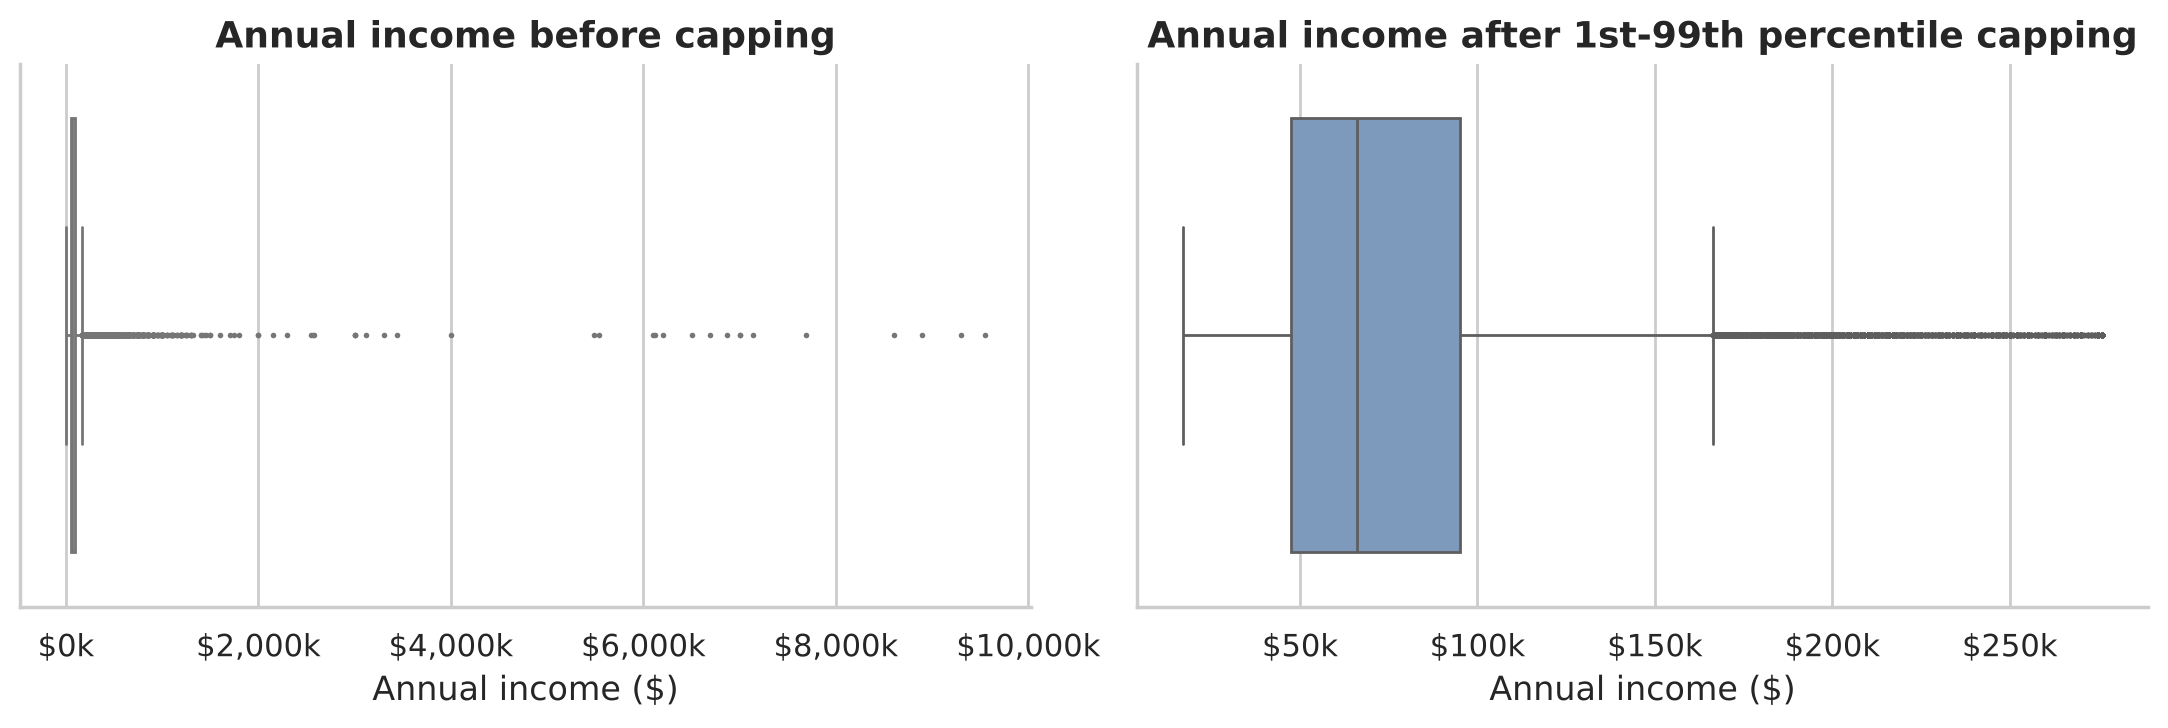

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(x=clean["annual_inc"], ax=ax[0], color=GS_LIGHT, fliersize=1)
ax[0].set(title="Annual income before capping", xlabel="Annual income ($)")
sns.boxplot(x=clean["annual_inc_capped"], ax=ax[1], color=GS_BLUE, fliersize=1)
ax[1].set(title="Annual income after 1st-99th percentile capping", xlabel="Annual income ($)")
for a in ax: a.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"${v/1000:,.0f}k"))
save("00_income_capping")

**Observation:** before capping, a handful of incomes up to $9.55M squash the whole box into the left edge; after capping, the typical range of $47k to $95k is easy to read.

## 4. Feature creation

In [11]:
DELINQUENT = ["In Grace Period", "Late (16-30 days)", "Late (31-120 days)"]

clean["bad_flag"] = clean["loan_status"].isin(["Charged Off", "Default"]).astype(int)
clean["resolved_flag"] = clean["loan_status"].isin(["Fully Paid", "Charged Off", "Default"]).astype(int)
clean["delinquent_flag"] = clean["loan_status"].isin(DELINQUENT).astype(int)
clean["npl_flag"] = clean["loan_status"].isin(["Late (31-120 days)", "Default", "Charged Off"]).astype(int)
clean["pti"] = clean["installment"] * 12 / clean["annual_inc"]
clean["income_band"] = pd.cut(clean["annual_inc"], bins=[0, 45_000, 60_000, 75_000, 100_000, np.inf], right=False,
                              labels=["<45k", "45k-60k", "60k-75k", "75k-100k", "100k+"])
clean["issue_month"] = clean["issue_d"].dt.month
clean["issue_ym"] = clean["issue_d"].dt.to_period("M").astype(str)
clean["scheduled_interest"] = clean["installment"] * clean["term_months"] - clean["funded_amount"]
clean["high_risk_flag"] = (clean["grade"].isin(["E", "F", "G"]) | (clean["pti"] > 0.15)
                           | (clean["delinquent_flag"] == 1)).astype(int)
clean["pti_band"] = pd.cut(clean["pti"], bins=[0, .05, .10, .15, .20, np.inf], right=False,
                           labels=["<5%", "5-10%", "10-15%", "15-20%", "20%+"])

res = clean[clean["resolved_flag"] == 1]          # finished loans: the base for every bad-loan rate

summary = pd.Series({
    "Loans": len(clean),
    "Resolved loans": clean["resolved_flag"].sum(),
    "Bad loans": clean["bad_flag"].sum(),
    "Bad-loan rate (resolved)": res["bad_flag"].mean(),
    "Bad-loan rate (all loans)": clean["bad_flag"].mean(),
    "Delinquent loans": clean["delinquent_flag"].sum(),
    "High-risk borrowers %": clean["high_risk_flag"].mean(),
    "Average PTI": clean["pti"].mean(),
    "Scheduled interest ($M)": clean["scheduled_interest"].sum() / 1e6,
})
summary.to_frame("value").style.format("{:,.3f}")

,value
Loans,"270,299.000"
Resolved loans,"94,224.000"
Bad loans,"17,863.000"
Bad-loan rate (resolved),0.190
Bad-loan rate (all loans),0.066
Delinquent loans,"5,614.000"
High-risk borrowers %,0.156
Average PTI,0.084
Scheduled interest ($M),"1,236.709"


**Observation:** the features reproduce the Part 1 and Part 2 numbers exactly: 94,224 resolved loans, 17,863 bad loans, a 19.0% bad-loan rate (6.6% on all loans), 5,614 delinquent loans and 15.6% high-risk borrowers.

## 5. Univariate analysis

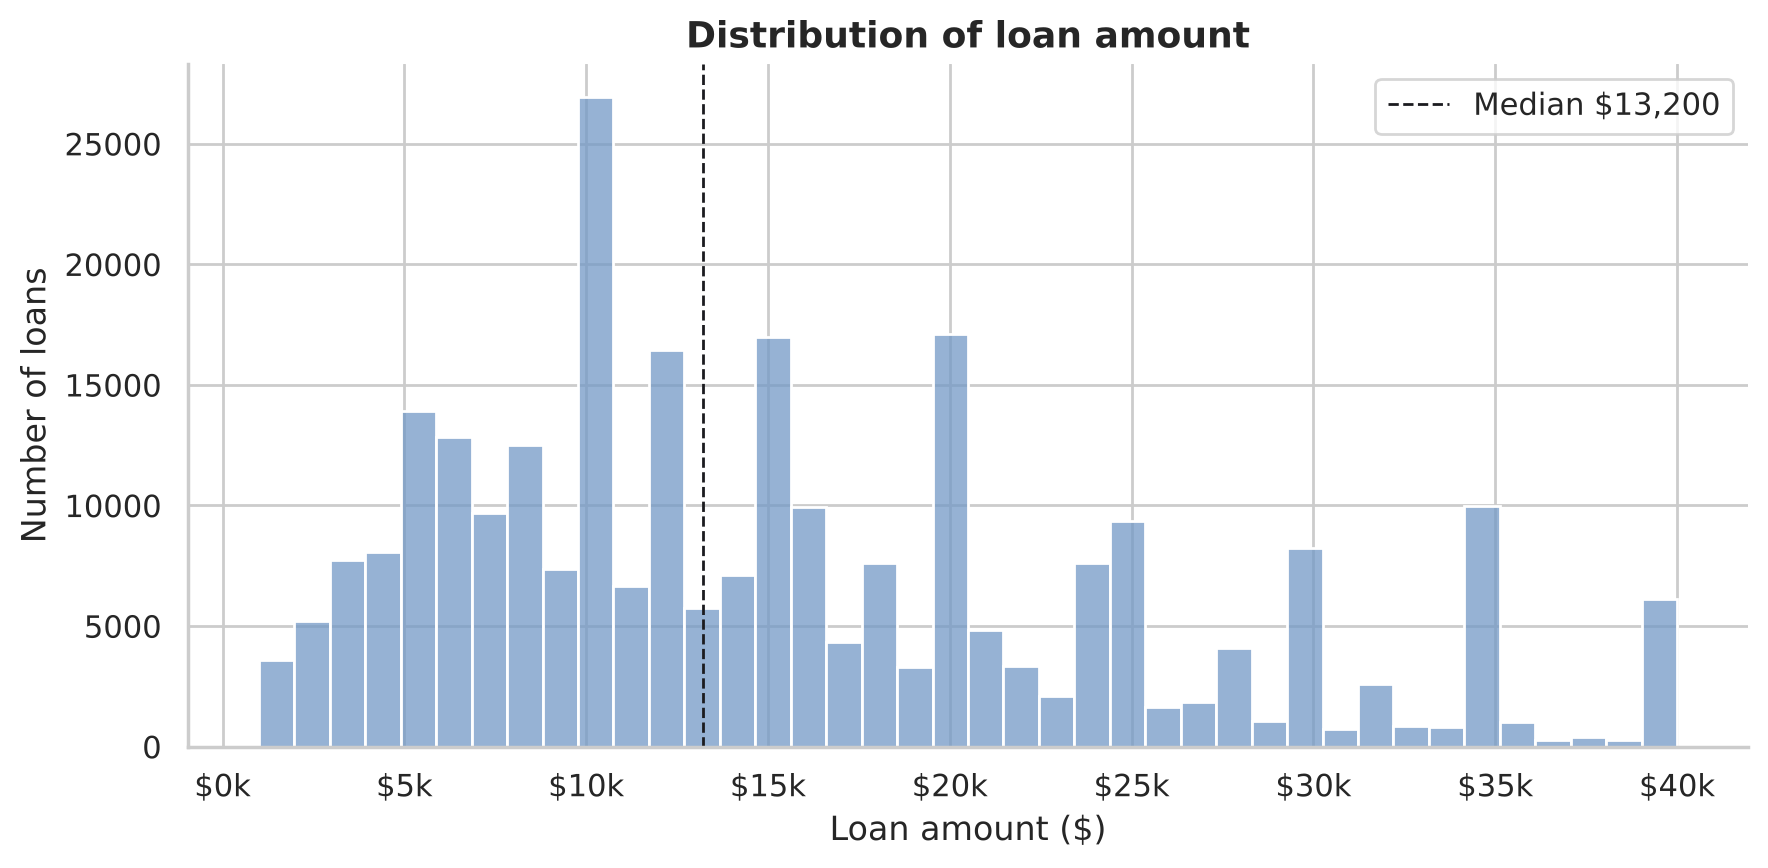

In [12]:
ax = sns.histplot(clean["loan_amount"], bins=40, color=GS_BLUE, edgecolor="white")
ax.set(title="Distribution of loan amount", xlabel="Loan amount ($)", ylabel="Number of loans")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"${v/1000:,.0f}k"))
ax.axvline(clean["loan_amount"].median(), color=GS_BLACK, ls="--", lw=1, label=f"Median ${clean['loan_amount'].median():,.0f}")
ax.legend()
save("01_loan_amount")

**Observation:** loan amounts run from $1,000 to $40,000 with a median of $13,200; spikes at round numbers ($10k, $15k, $20k) show borrowers ask for round sums.

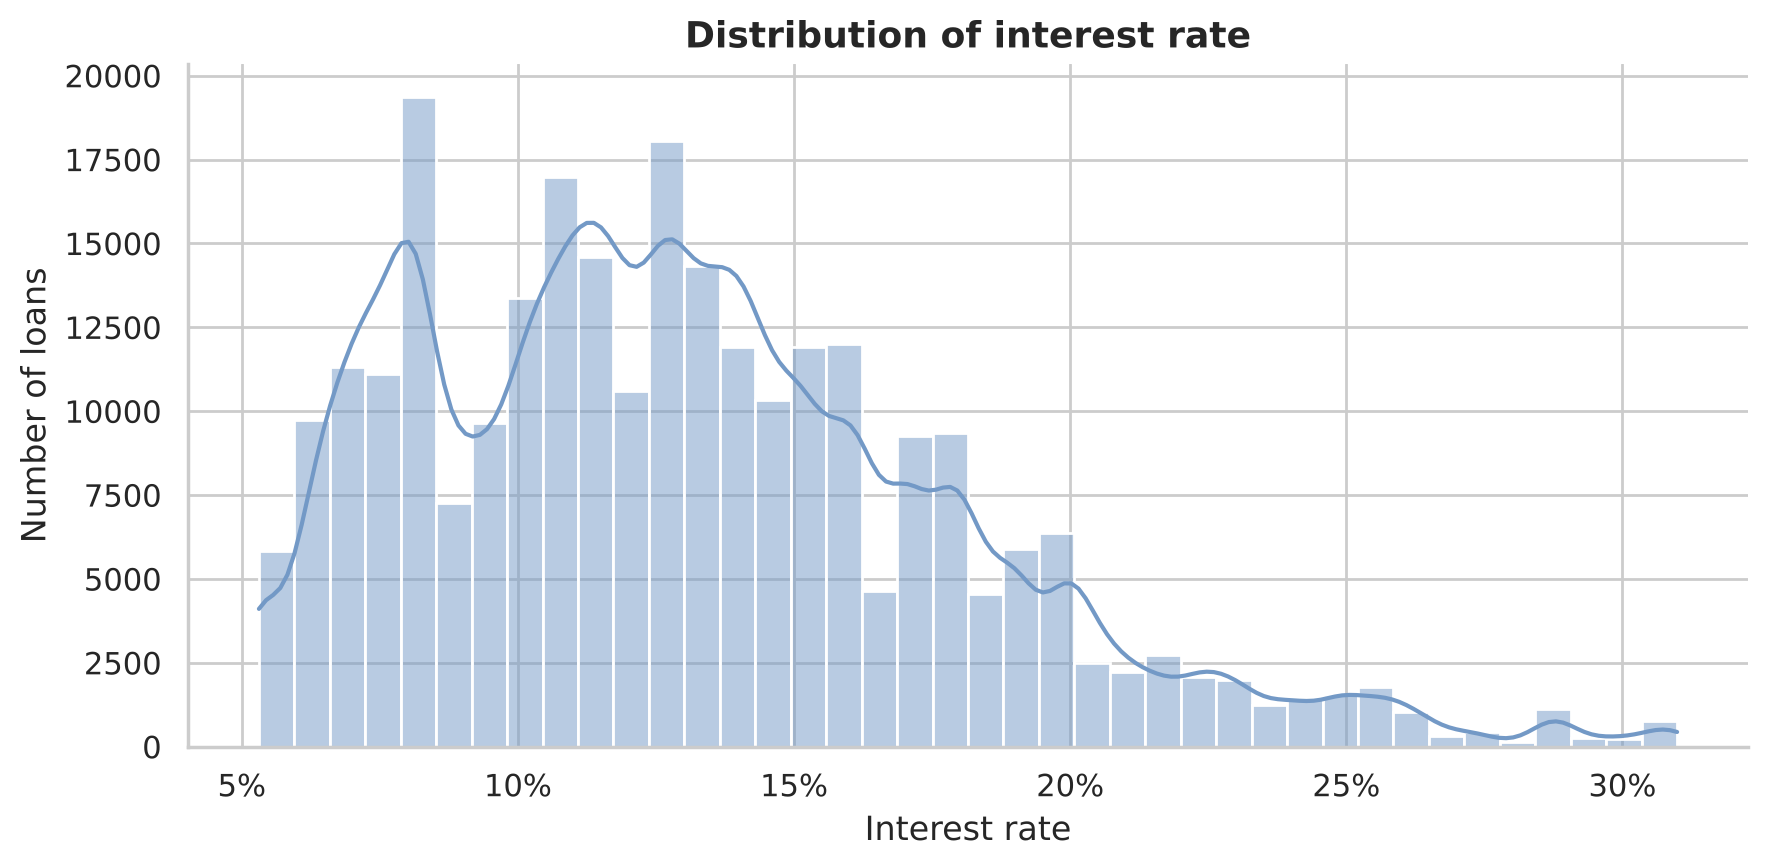

In [13]:
ax = sns.histplot(clean["int_rate"], bins=40, kde=True, color=GS_BLUE, edgecolor="white")
ax.set(title="Distribution of interest rate", xlabel="Interest rate", ylabel="Number of loans")
ax.xaxis.set_major_formatter(pct)
save("02_int_rate")

**Observation:** 80% of loans are priced between 7.2% and 19.7% (mean 13.08%); the long right tail above 20% belongs to grades E to G.

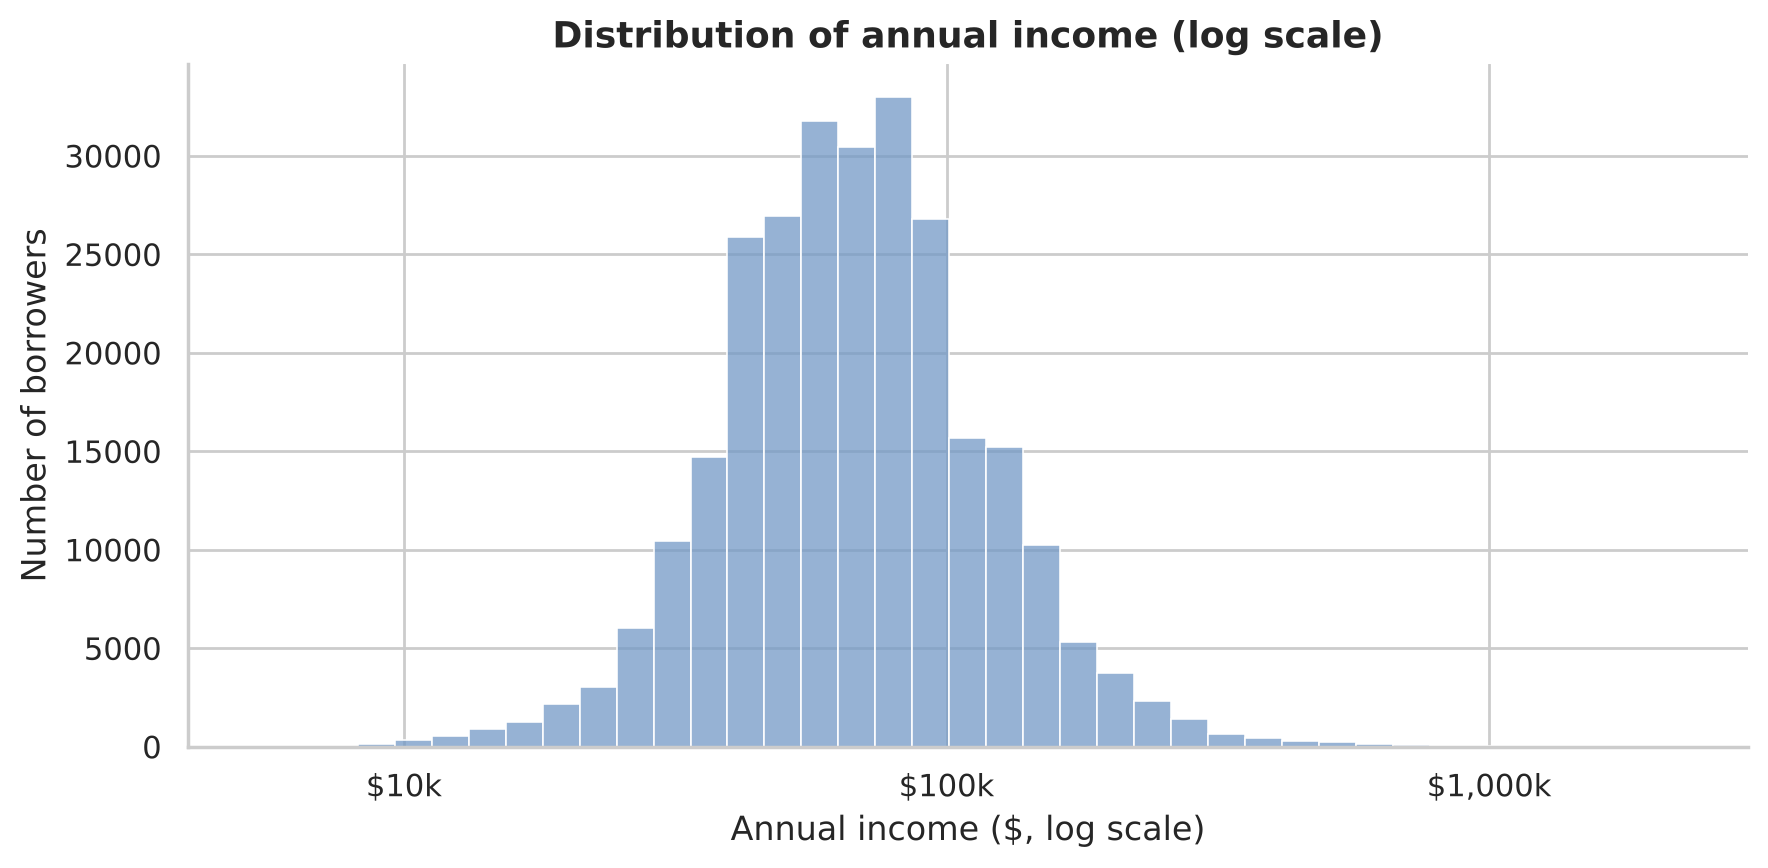

In [14]:
ax = sns.histplot(clean["annual_inc"], bins=80, log_scale=True, color=GS_BLUE, edgecolor="white")
ax.set_xlim(4_000, 3_000_000)
ax.set(title="Distribution of annual income (log scale)", xlabel="Annual income ($, log scale)", ylabel="Number of borrowers")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"${v/1000:,.0f}k"))
save("03_annual_inc_log")

**Observation:** on a log scale income is close to bell-shaped around a median of $66,000; the mean ($79,618) sits higher because of a few very large incomes.

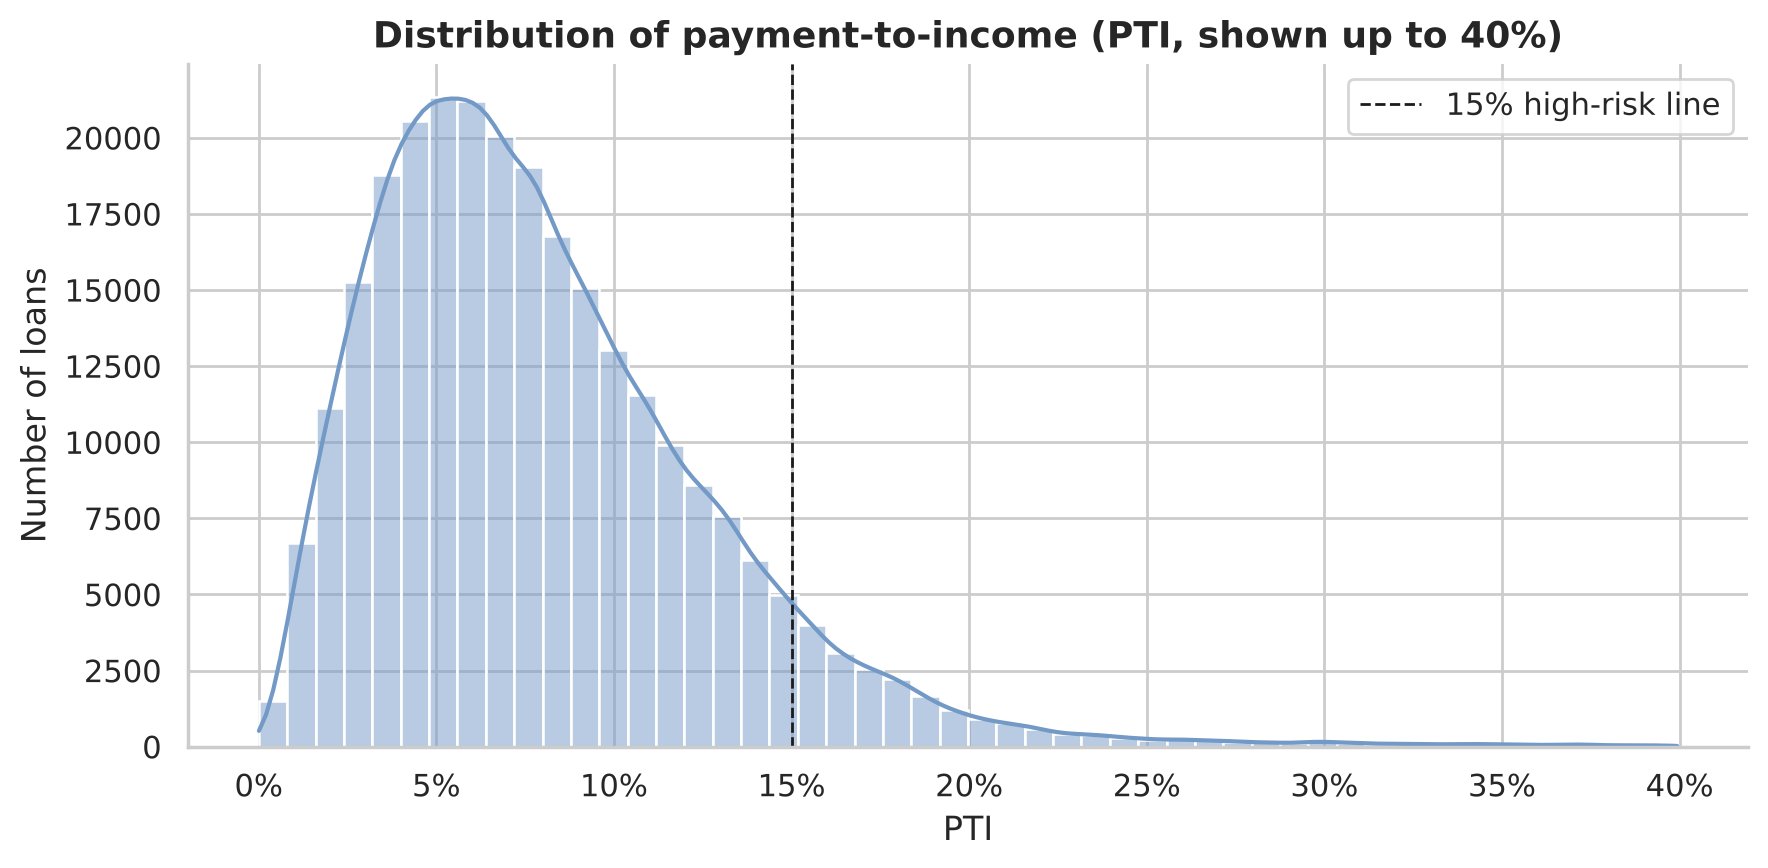

In [15]:
ax = sns.histplot(clean.loc[clean["pti"] <= 0.4, "pti"], bins=50, kde=True, color=GS_BLUE, edgecolor="white")
ax.set(title="Distribution of payment-to-income (PTI, shown up to 40%)", xlabel="PTI", ylabel="Number of loans")
ax.xaxis.set_major_formatter(pct)
ax.axvline(0.15, color=GS_BLACK, ls="--", lw=1, label="15% high-risk line")
ax.legend()
save("04_pti")

**Observation:** the median borrower spends 7.1% of income on the loan payment (mean 8.4%); 8.2% of loans sit above the 15% high-risk line.

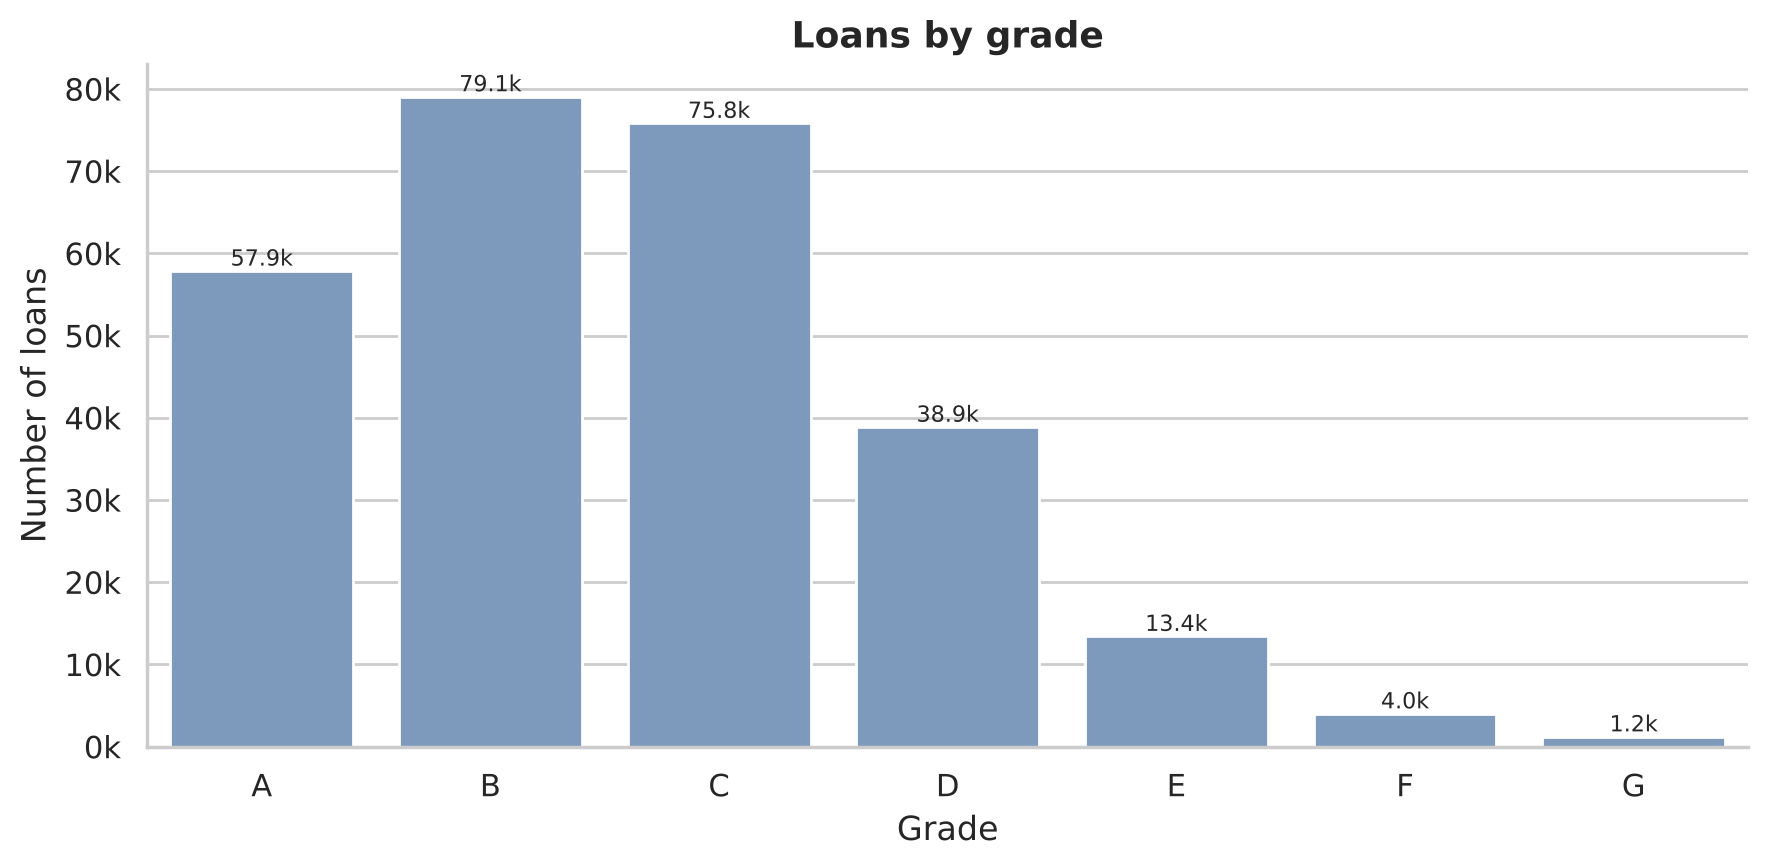

In [16]:
def countplot(col, title, order=None, rotate=0, fname=None):
    order = order if order is not None else clean[col].value_counts().index
    ax = sns.countplot(data=clean, x=col, order=order, color=GS_BLUE)
    ax.set(title=title, xlabel=col.replace("_", " ").title(), ylabel="Number of loans")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v/1000:,.0f}k"))
    for c in ax.containers:
        ax.bar_label(c, labels=[f"{v/1000:,.1f}k" if v >= 1000 else f"{v:,.0f}" for v in c.datavalues], fontsize=8)
    plt.xticks(rotation=rotate, ha="right" if rotate else "center")
    save(fname)

countplot("grade", "Loans by grade", order=list("ABCDEFG"), fname="05_count_grade")

**Observation:** grades B (79,072) and C (75,840) make up 57% of loans; grades E to G together are only 6.9%.

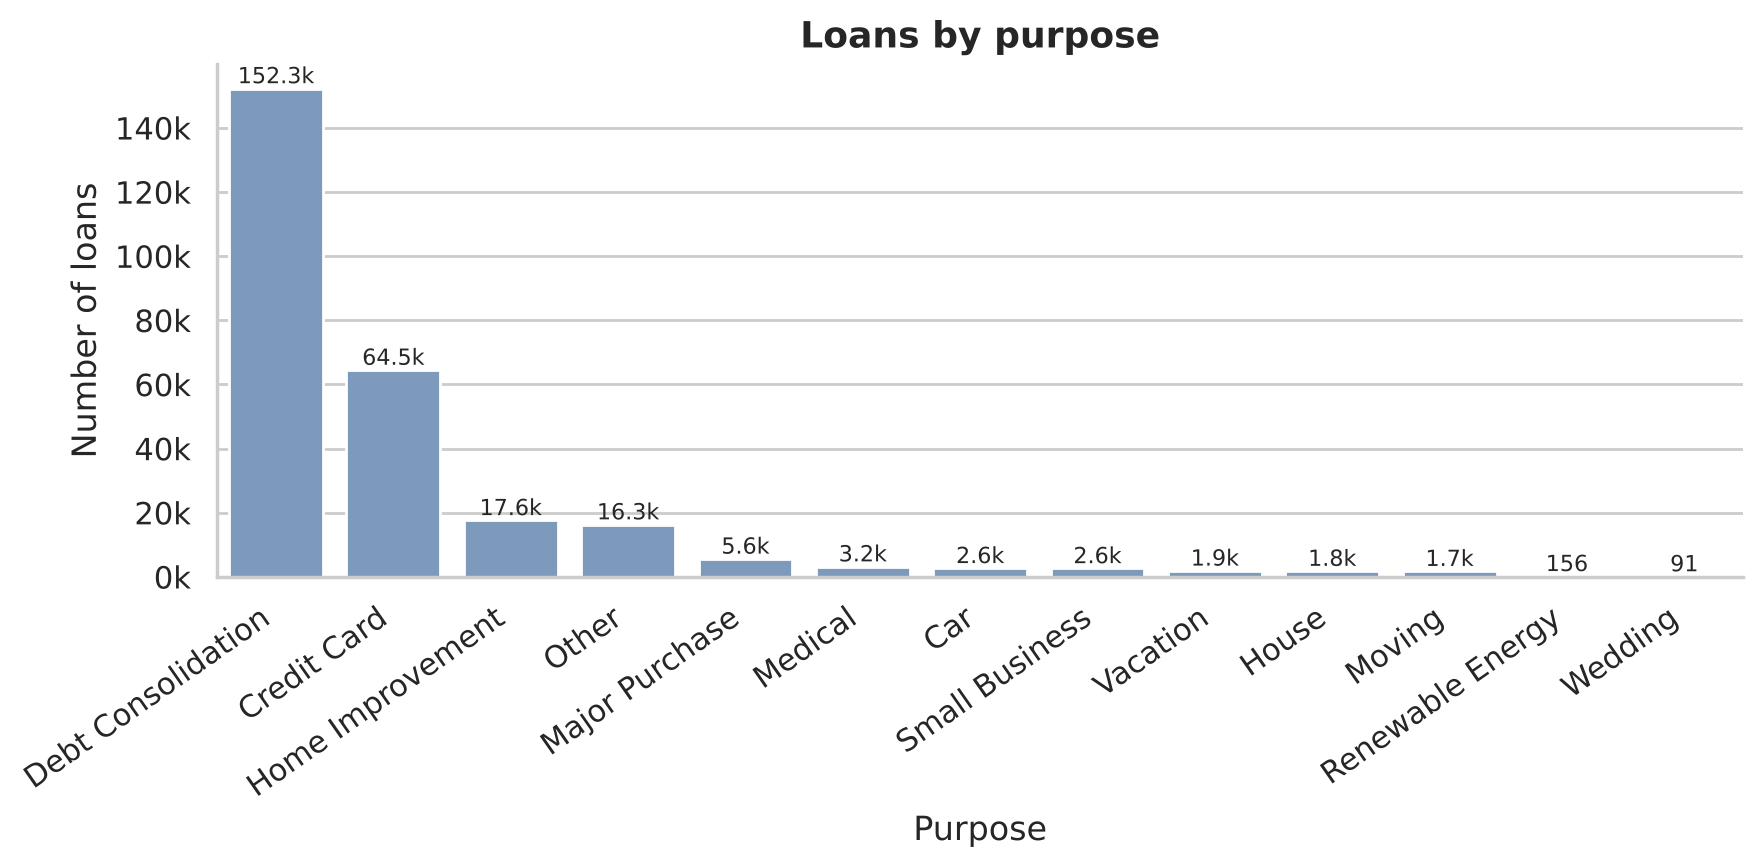

In [17]:
countplot("purpose", "Loans by purpose", rotate=35, fname="06_count_purpose")

**Observation:** debt consolidation (152,285 loans, 56%) and credit card (64,477, 24%) dominate; the other 11 purposes share the last 20%.

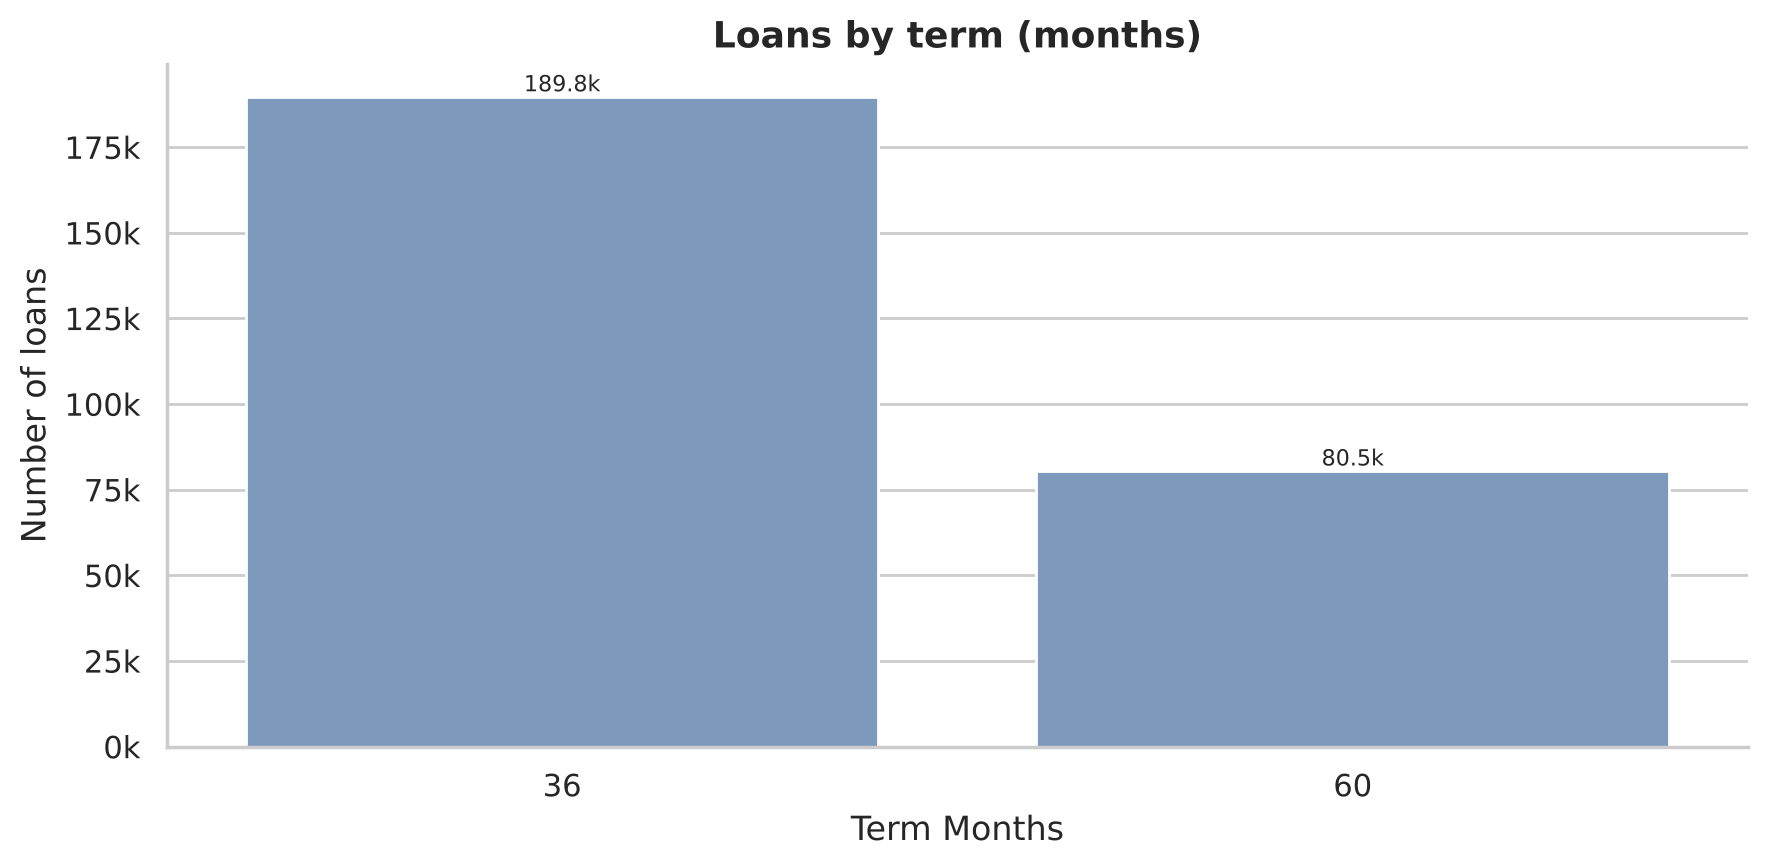

In [18]:
countplot("term_months", "Loans by term (months)", fname="07_count_term")

**Observation:** 70.2% of loans are 36-month and 29.8% are 60-month.

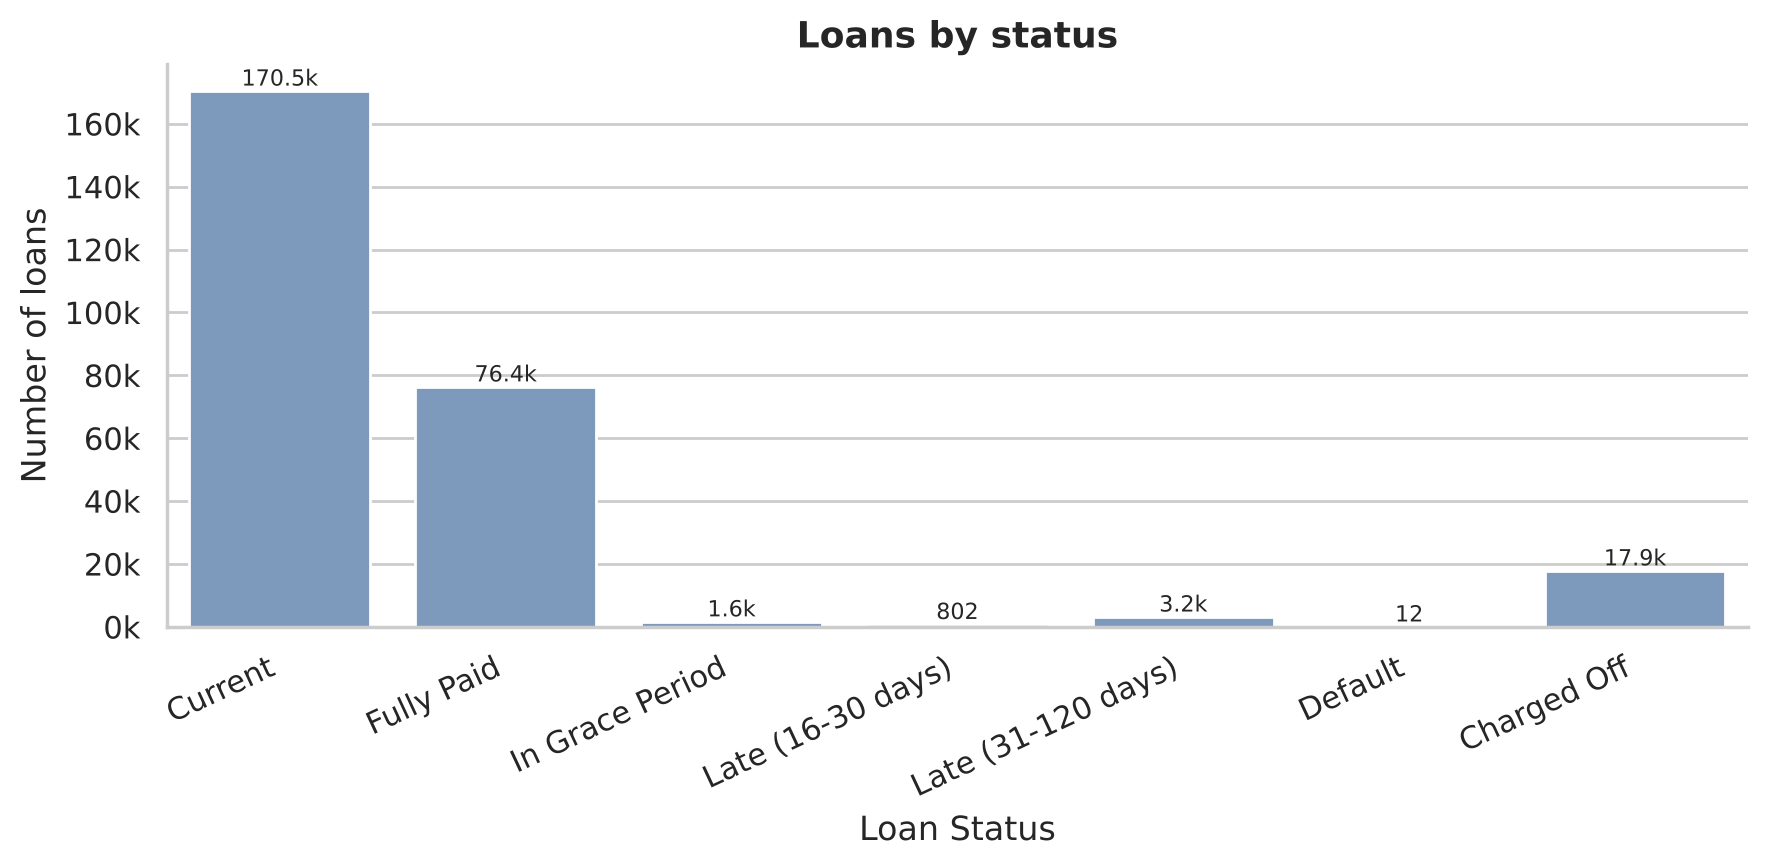

In [19]:
status_order = ["Current", "Fully Paid", "In Grace Period", "Late (16-30 days)", "Late (31-120 days)", "Default", "Charged Off"]
countplot("loan_status", "Loans by status", order=status_order, rotate=25, fname="08_count_status")

**Observation:** 63.1% of loans are still Current and 28.3% are Fully Paid; only 6.6% are Charged Off, which is why the bad-loan rate must use resolved loans.

## 6. Bivariate and multivariate analysis

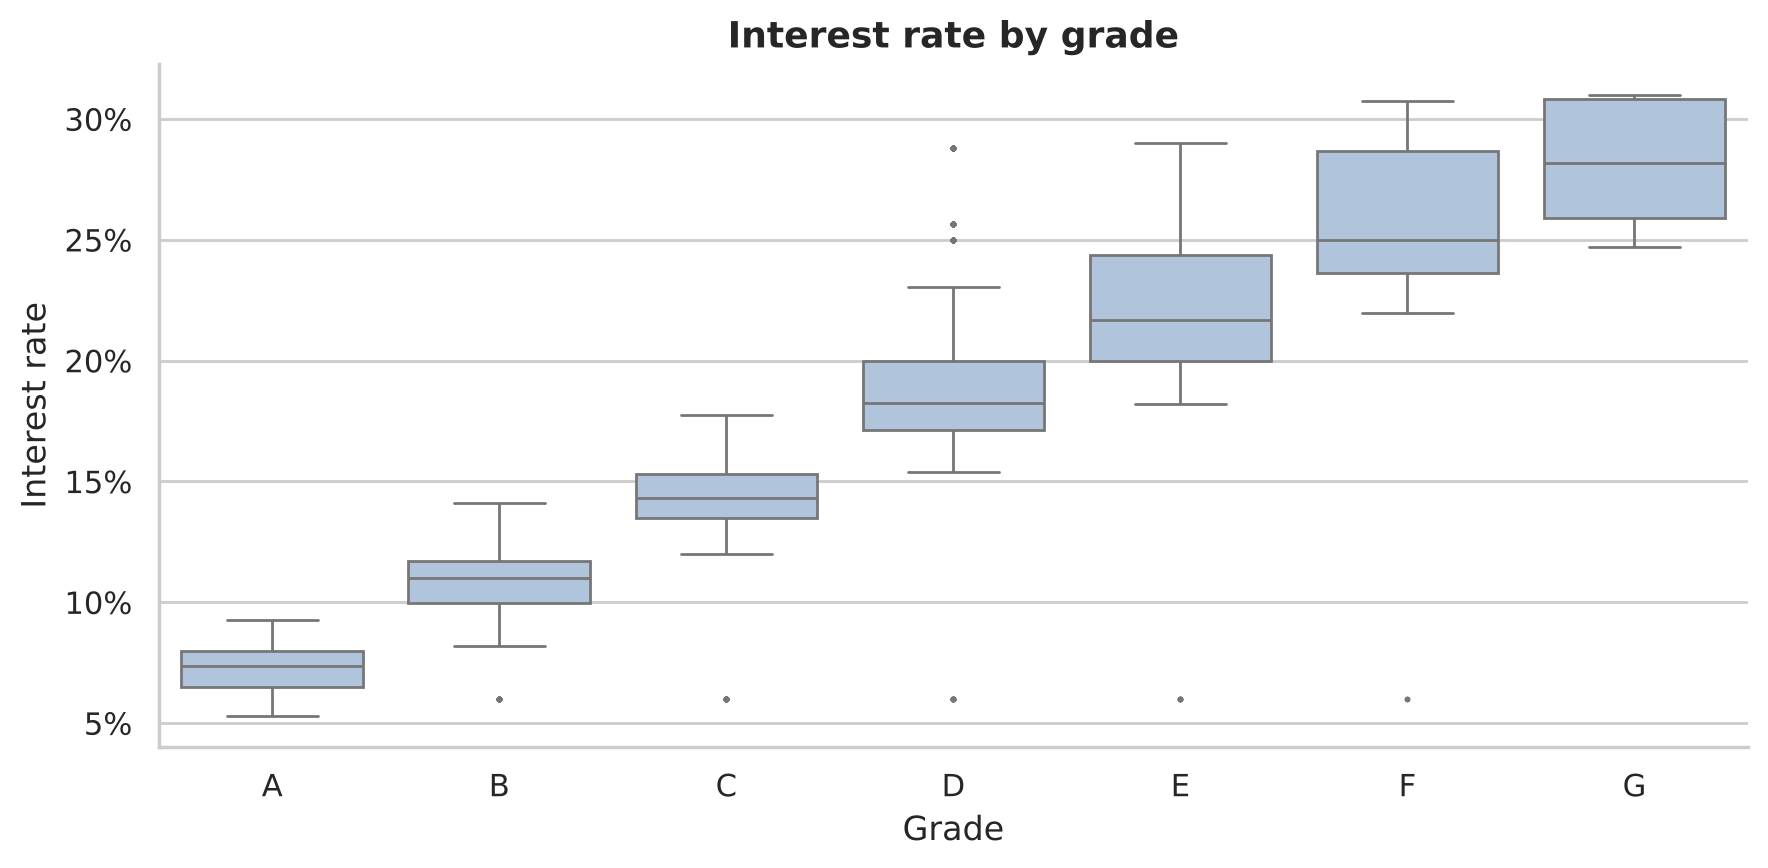

In [20]:
ax = sns.boxplot(data=clean, x="grade", y="int_rate", order=list("ABCDEFG"), color=GS_LIGHT, fliersize=1)
ax.set(title="Interest rate by grade", xlabel="Grade", ylabel="Interest rate")
ax.yaxis.set_major_formatter(pct)
save("09_box_rate_grade")

**Observation:** the median rate climbs from 7.4% at grade A to 28.2% at grade G, and the boxes barely overlap, so grade sets the price.

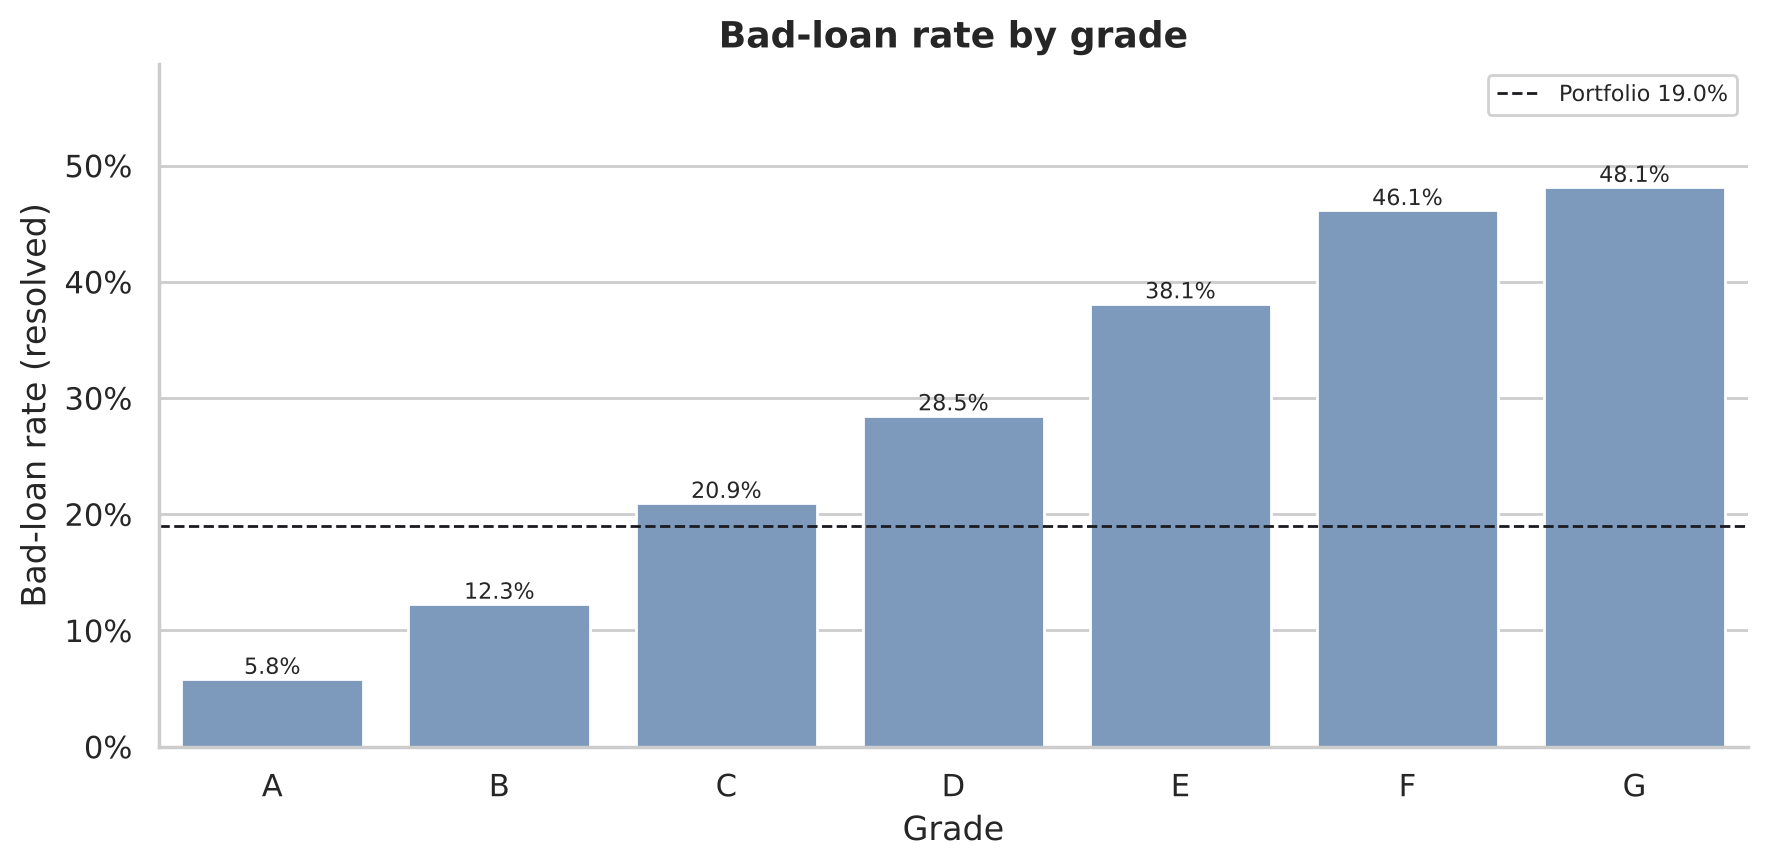

,bad_rate,resolved
grade,,
A,0.058065,16671
B,0.122690,26897
C,0.209443,26580
D,0.284808,14494
E,0.381188,6666
F,0.461470,2245
G,0.481371,671


In [21]:
def bad_rate_bar(col, title, order=None, fname=None, rotate=0):
    t = res.groupby(col, observed=True)["bad_flag"].agg(["mean", "size"]).rename(columns={"mean": "bad_rate", "size": "resolved"})
    t = t.loc[order] if order is not None else t.sort_values("bad_rate", ascending=False)
    ax = sns.barplot(x=t.index.astype(str), y=t["bad_rate"], color=GS_BLUE)
    ax.axhline(res["bad_flag"].mean(), color=GS_BLACK, ls="--", lw=1, label="Portfolio 19.0%")
    ax.set(title=title, xlabel=col.replace("_", " ").title(), ylabel="Bad-loan rate (resolved)")
    ax.yaxis.set_major_formatter(pct)
    ax.bar_label(ax.containers[0], labels=[f"{v:.1%}" for v in t["bad_rate"]], fontsize=8)
    ax.set_ylim(0, t["bad_rate"].max() * 1.22)
    ax.legend(loc="best", fontsize=8, framealpha=0.9)
    plt.xticks(rotation=rotate, ha="right" if rotate else "center")
    save(fname)
    return t

bad_rate_bar("grade", "Bad-loan rate by grade", order=list("ABCDEFG"), fname="10_bad_grade")

**Observation:** the bad-loan rate rises at every grade, from 5.8% at A to 48.1% at G, an 8 times jump.

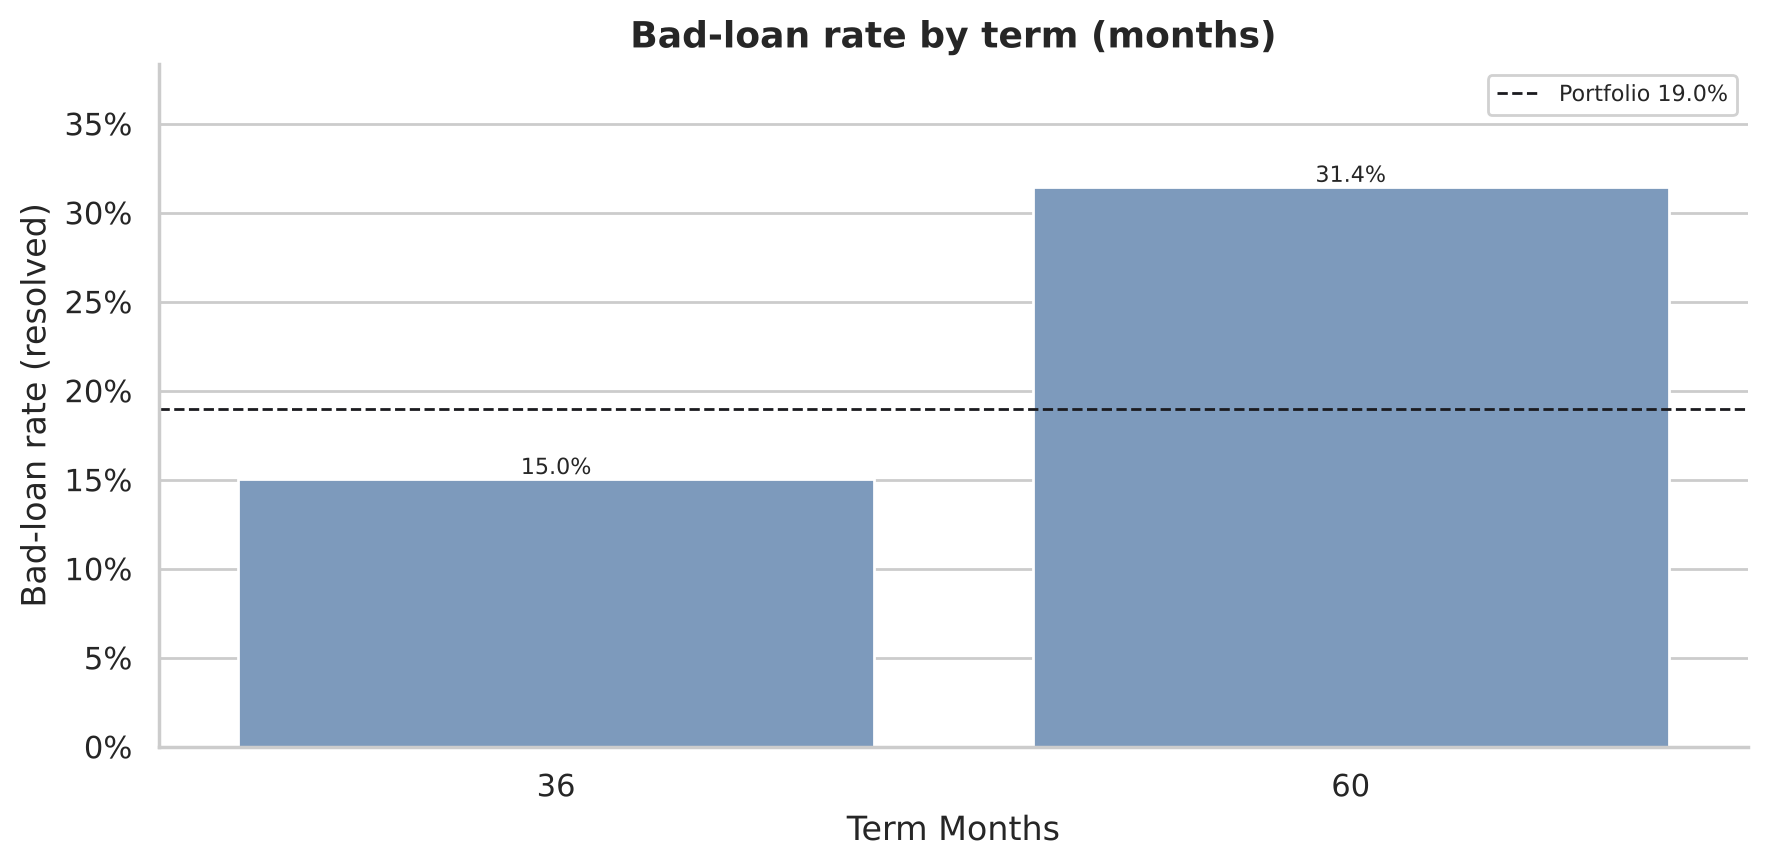

,bad_rate,resolved
term_months,,
36,0.150161,71590
60,0.314262,22634


In [22]:
bad_rate_bar("term_months", "Bad-loan rate by term (months)", order=[36, 60], fname="11_bad_term")

**Observation:** 60-month loans go bad 31.4% of the time, more than double the 15.0% for 36-month loans.

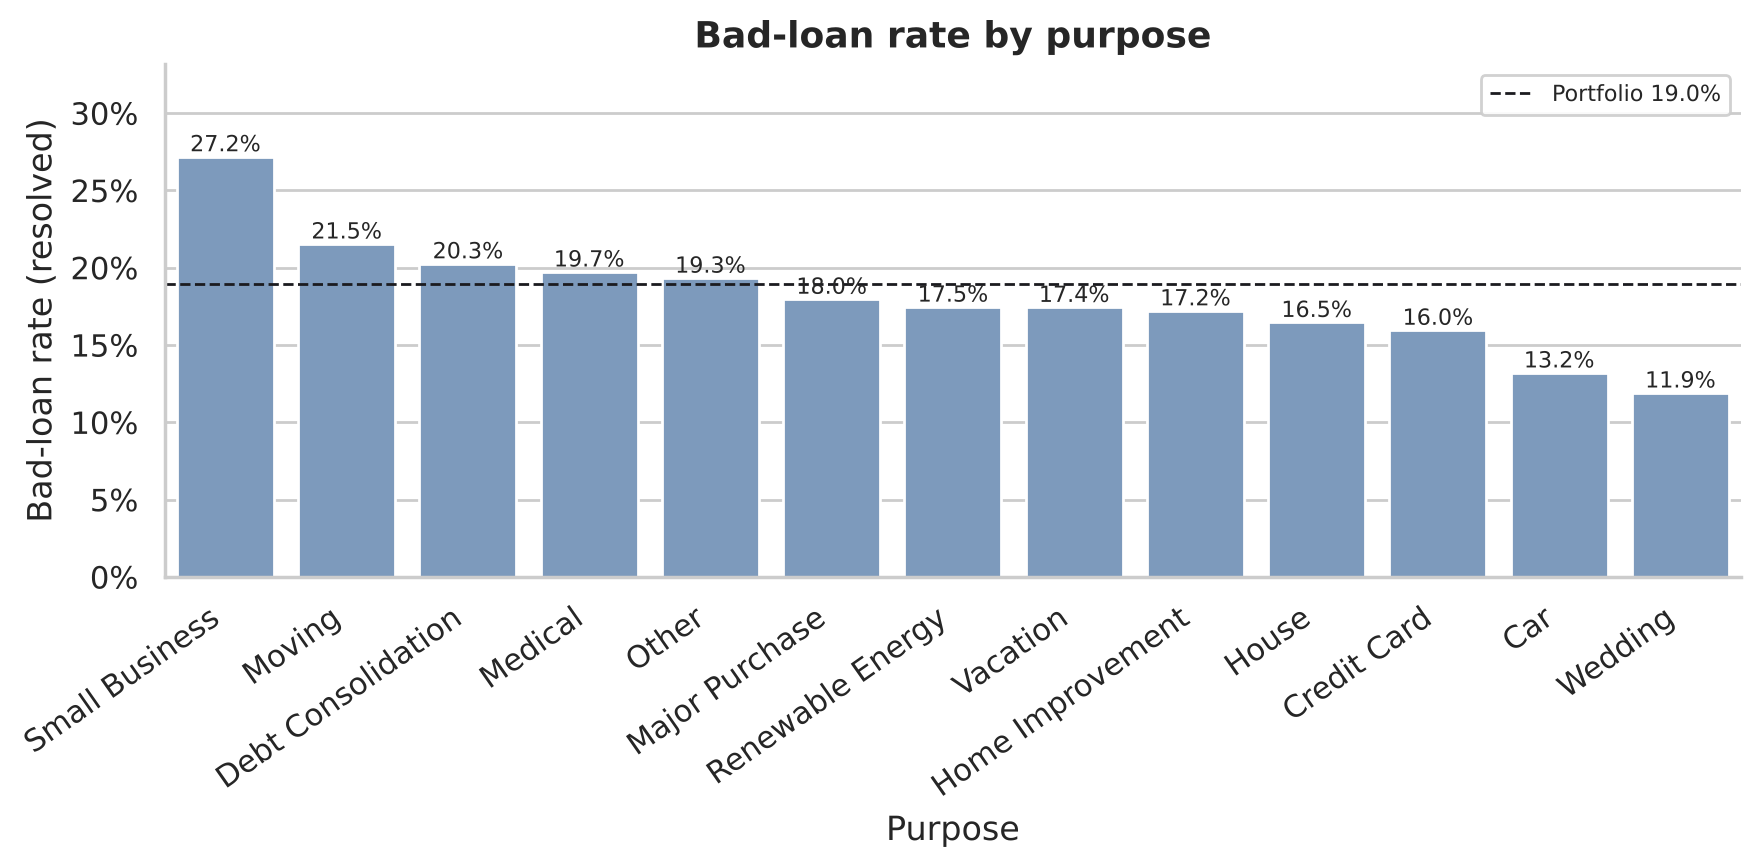

,bad_rate,resolved
purpose,,
Small Business,0.271855,938
Moving,0.215429,687
Debt Consolidation,0.202614,55174
Medical,0.197318,1044
Other,0.193328,5126
Major Purchase,0.179692,1881
Renewable Energy,0.174603,63
Vacation,0.174400,625
Home Improvement,0.172187,5918


In [23]:
bad_rate_bar("purpose", "Bad-loan rate by purpose", fname="12_bad_purpose", rotate=35)

**Observation:** small business is the riskiest purpose at 27.2%; wedding (11.9%) and car (13.2%) are the safest.

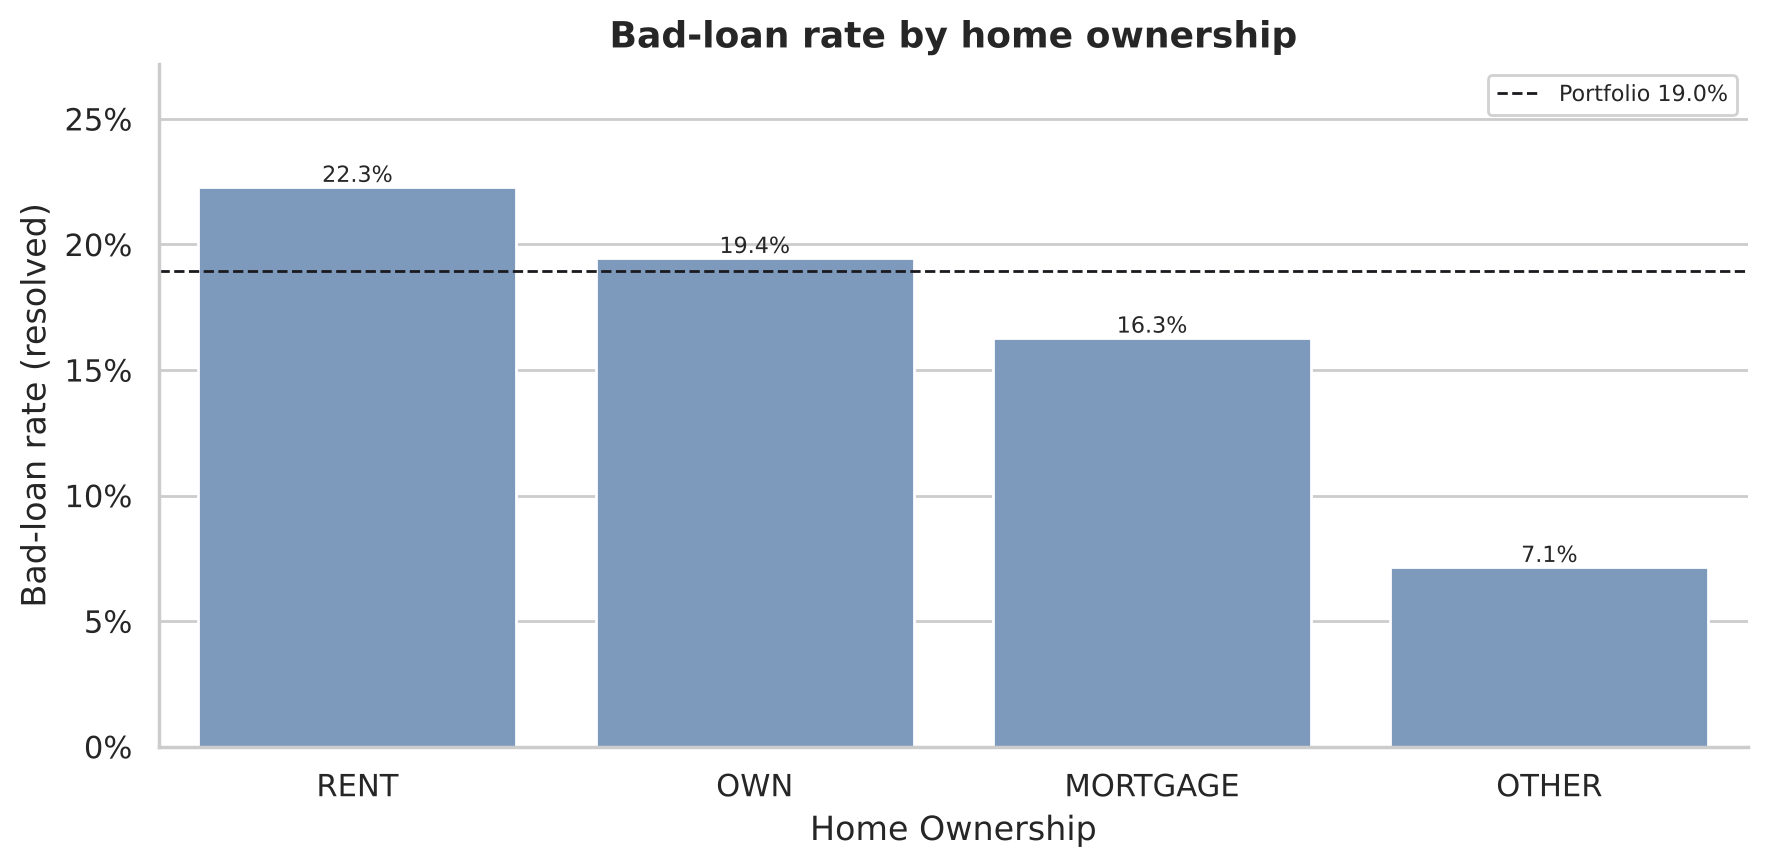

,bad_rate,resolved
home_ownership,,
RENT,0.222793,36774
OWN,0.194474,10243
MORTGAGE,0.162754,47151
OTHER,0.071429,56


In [24]:
bad_rate_bar("home_ownership", "Bad-loan rate by home ownership", order=["RENT", "OWN", "MORTGAGE", "OTHER"], fname="13_bad_home")

**Observation:** renters go bad 22.3% of the time against 16.3% for borrowers with a mortgage; OTHER has too few loans (56 resolved) to read.

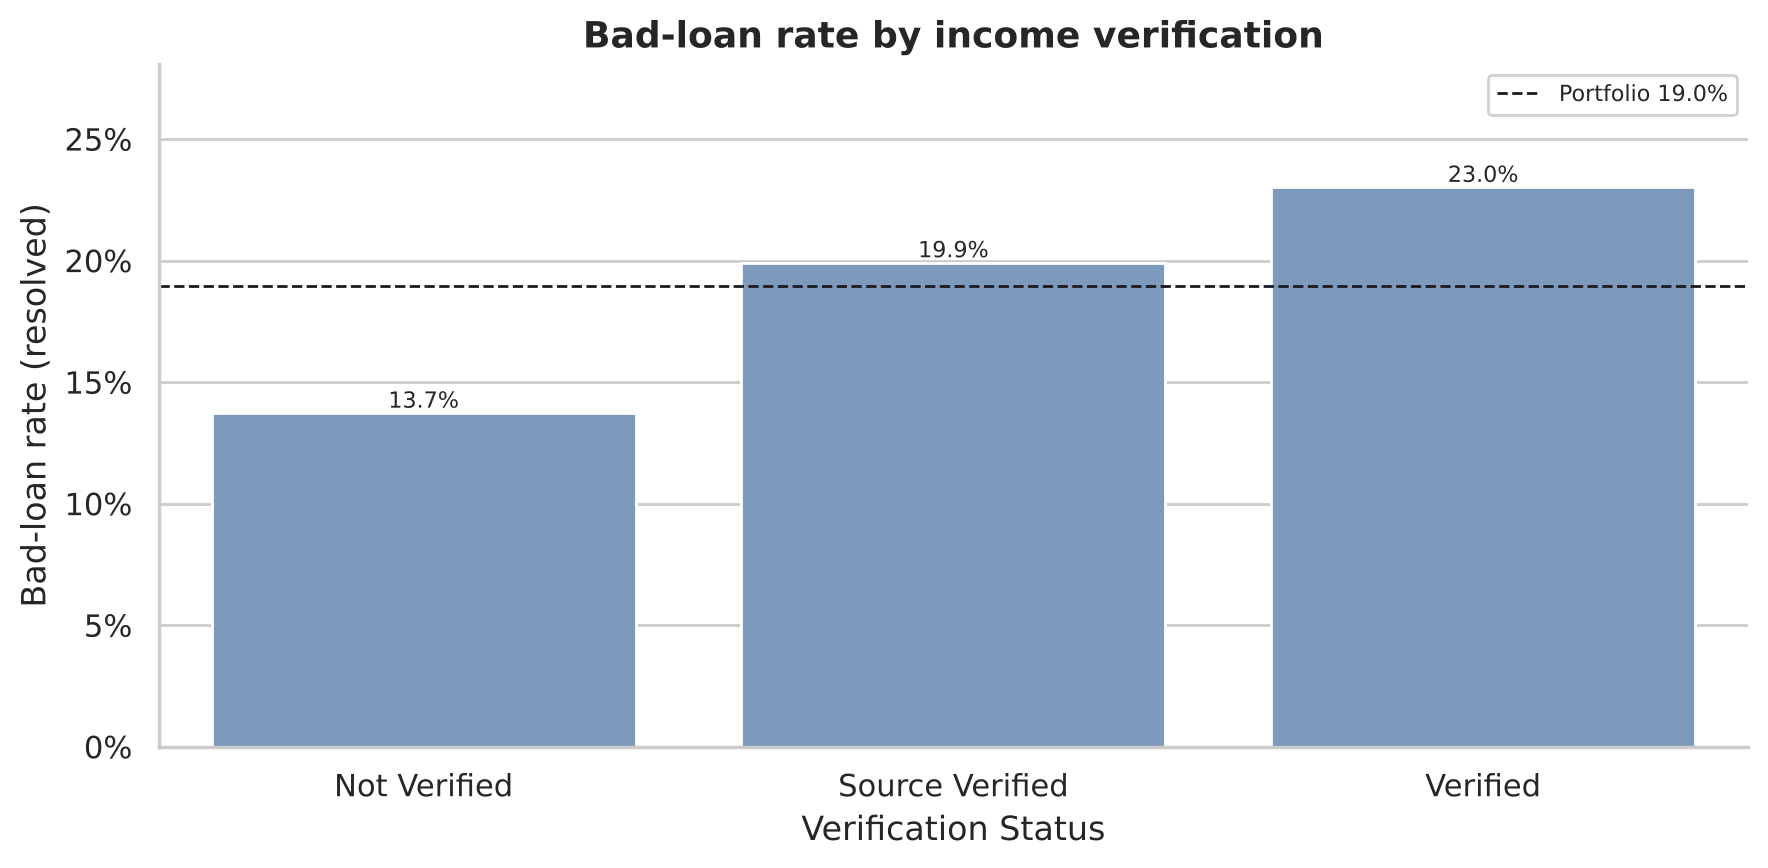

,bad_rate,resolved
verification_status,,
Not Verified,0.137262,29003
Source Verified,0.199155,36429
Verified,0.230168,28792


In [25]:
bad_rate_bar("verification_status", "Bad-loan rate by income verification", order=["Not Verified", "Source Verified", "Verified"], fname="14_bad_verification")

**Observation:** verified-income loans fail more (23.0%) than unverified ones (13.7%), because lenders ask riskier applicants to prove their income.

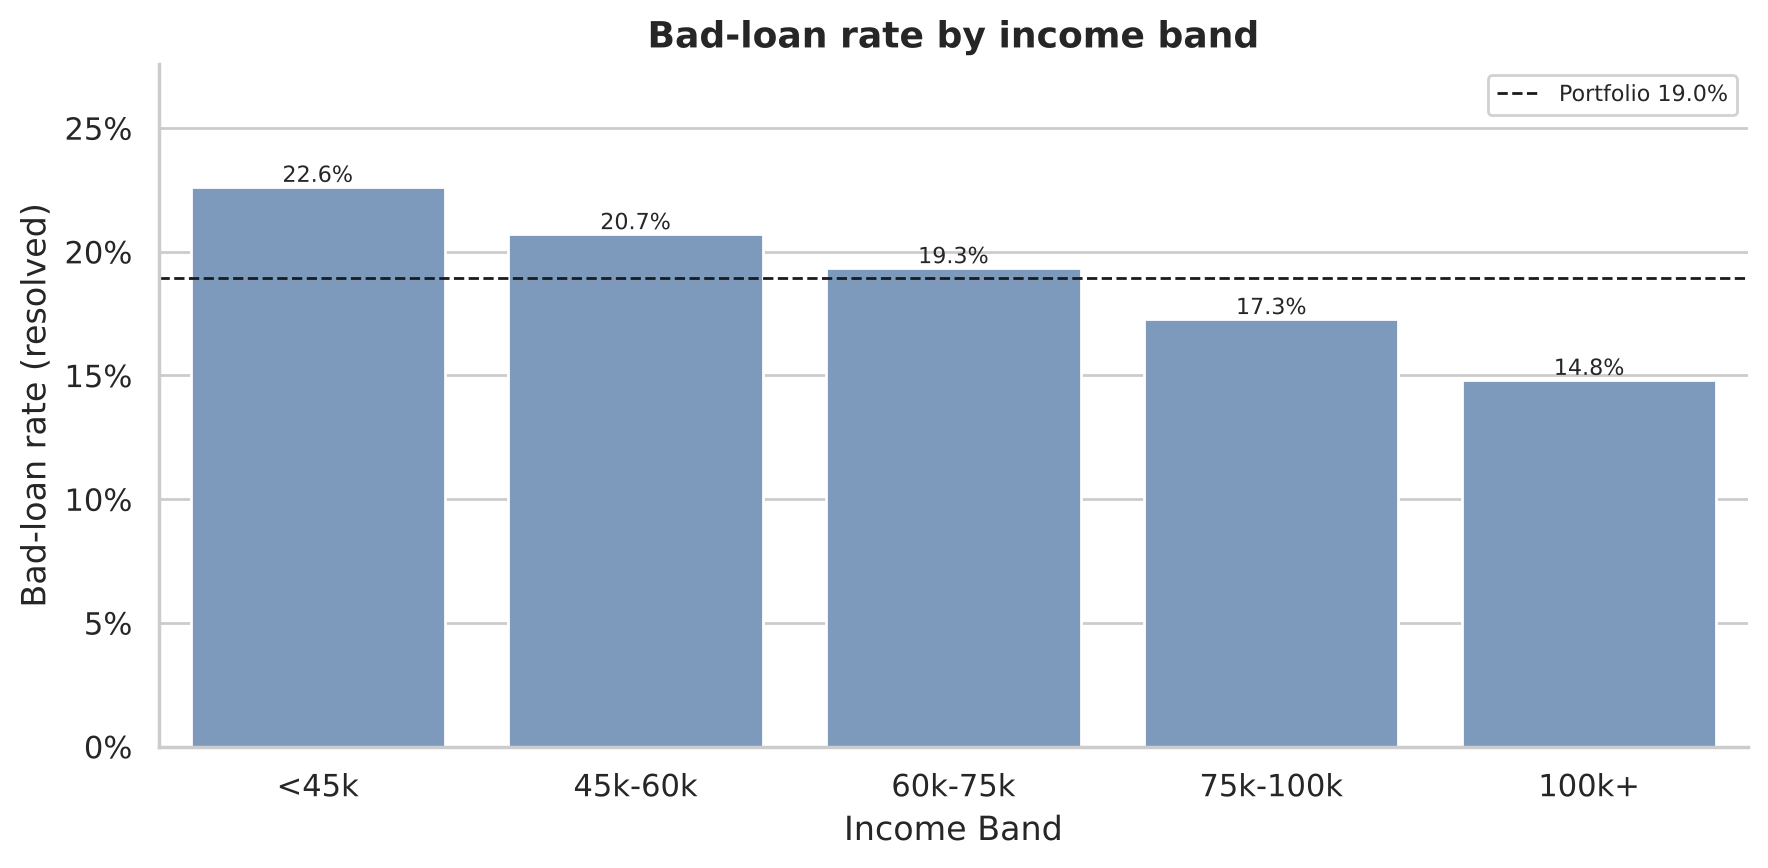

,bad_rate,resolved
income_band,,
<45k,0.226113,20388
45k-60k,0.207001,18483
60k-75k,0.193259,17386
75k-100k,0.172683,18062
100k+,0.148103,19905


In [26]:
bad_rate_bar("income_band", "Bad-loan rate by income band", order=["<45k", "45k-60k", "60k-75k", "75k-100k", "100k+"], fname="15_bad_income")

**Observation:** the bad-loan rate falls at every income step, from 22.6% under $45k to 14.8% at $100k and above.

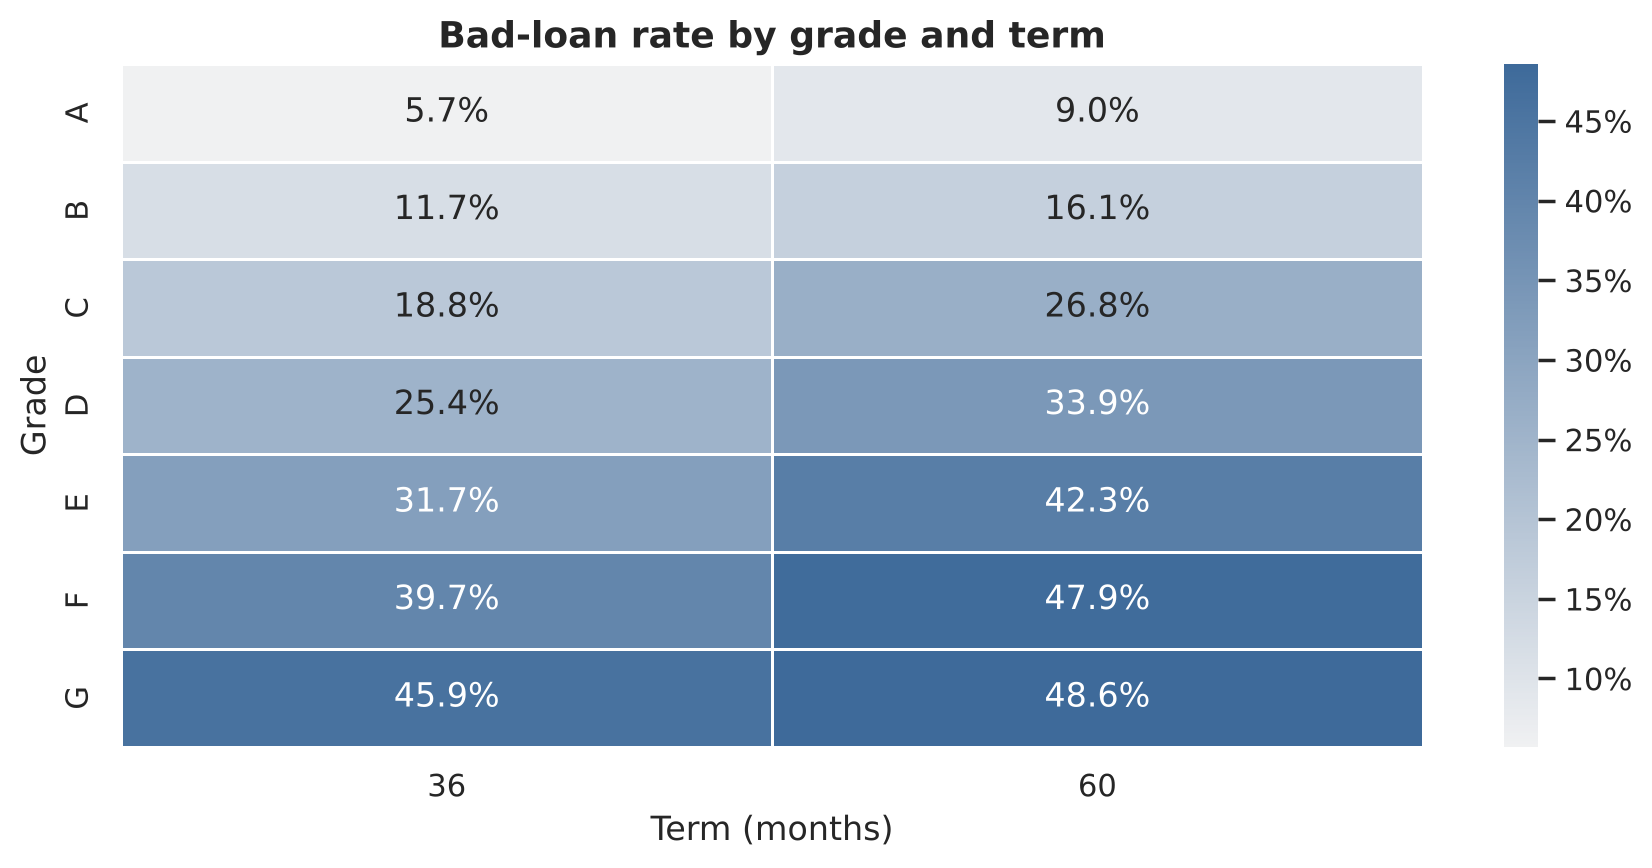

In [27]:
grade_term = res.pivot_table(index="grade", columns="term_months", values="bad_flag", aggfunc="mean")
ax = sns.heatmap(grade_term, annot=True, fmt=".1%", cmap=GS_SEQ, cbar_kws={"format": pct}, linewidths=.5)
ax.set(title="Bad-loan rate by grade and term", xlabel="Term (months)", ylabel="Grade")
save("16_heat_grade_term")

**Observation:** risk climbs down the grades and across to 60 months; grade C at 60 months (26.8%) is already riskier than grade D at 36 months (25.4%).

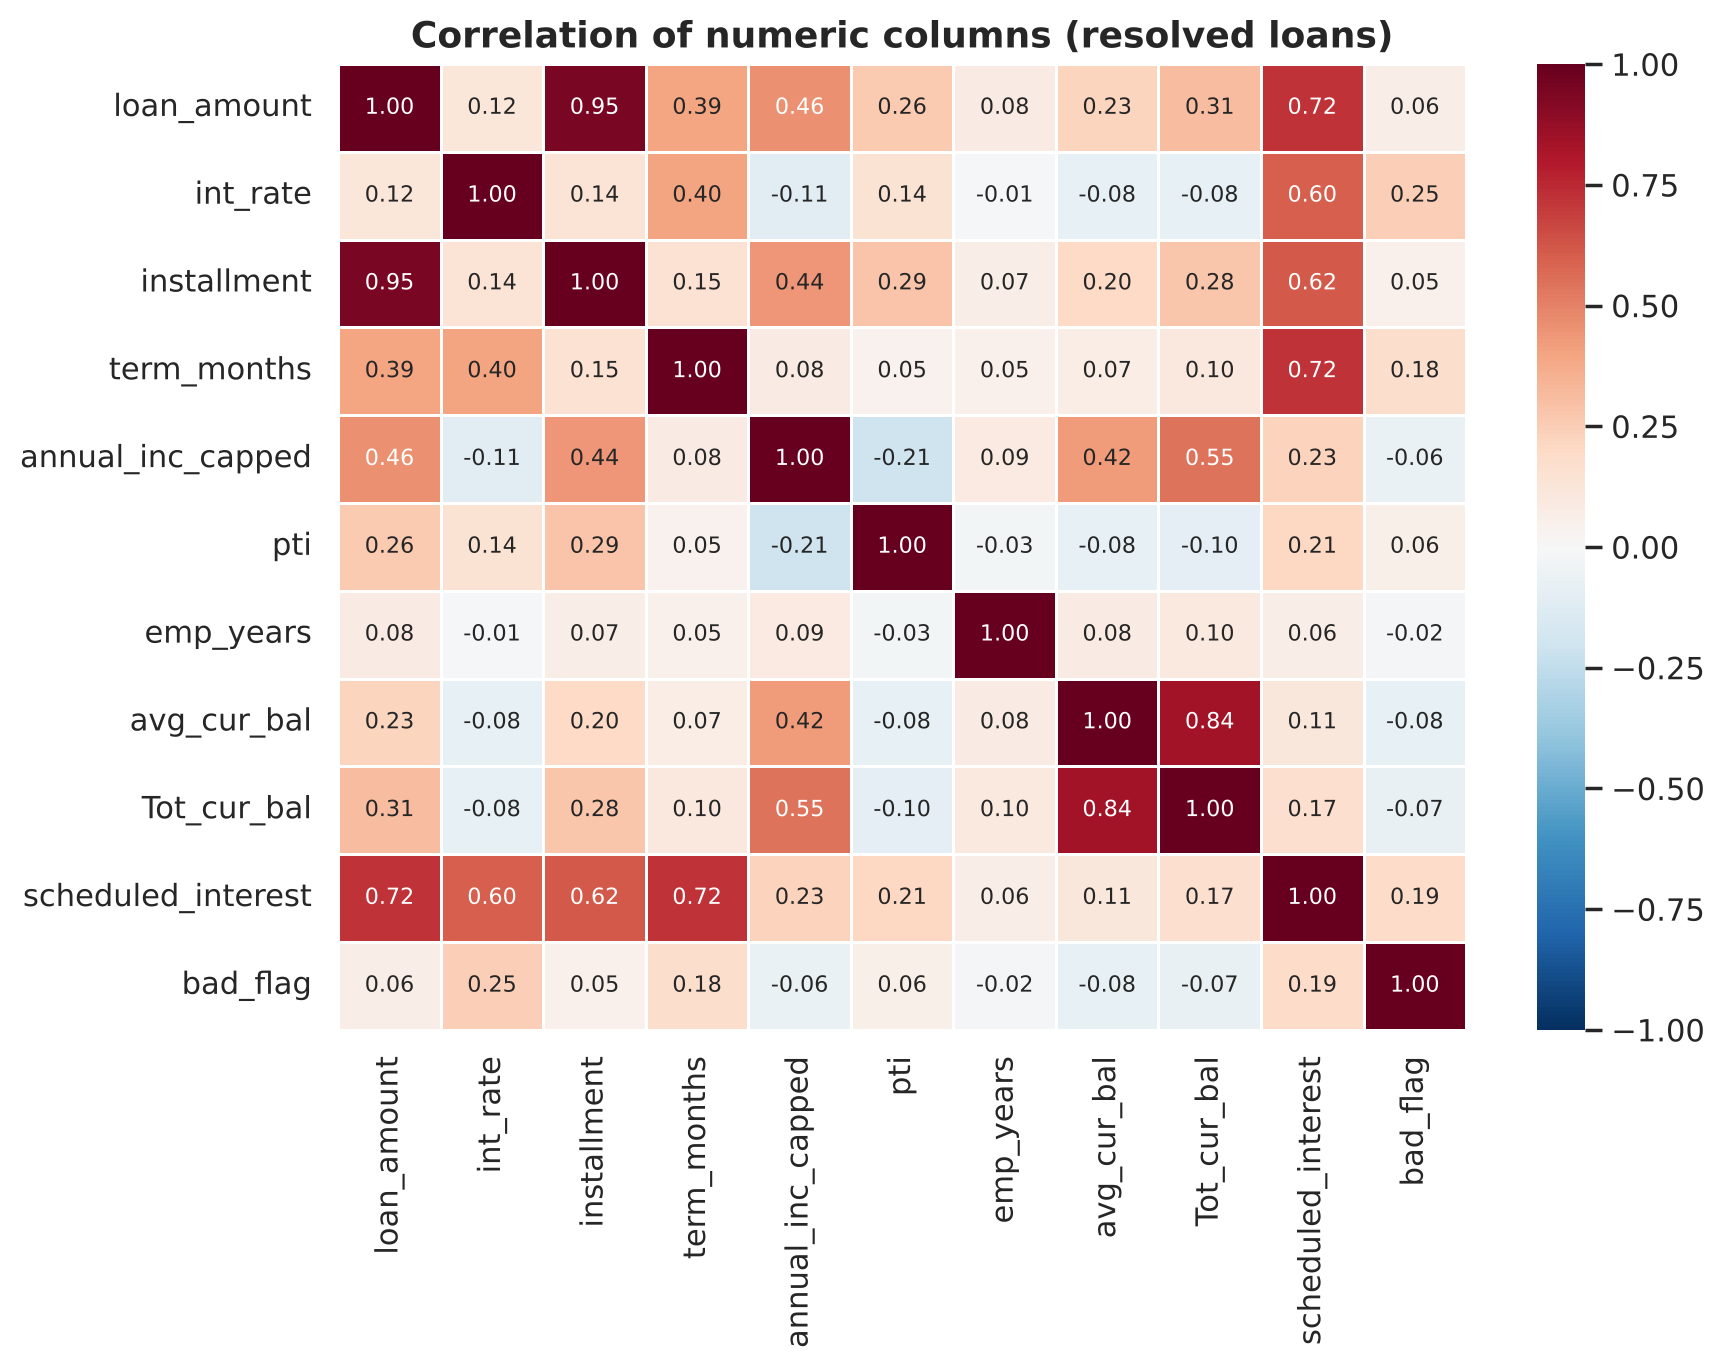

In [28]:
num_cols = ["loan_amount", "int_rate", "installment", "term_months", "annual_inc_capped", "pti",
            "emp_years", "avg_cur_bal", "Tot_cur_bal", "scheduled_interest", "bad_flag"]
corr = res[num_cols].corr()
plt.figure(figsize=(9, 7))
ax = sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5, annot_kws={"size": 8})
ax.set_title("Correlation of numeric columns (resolved loans)")
save("17_corr")

**Observation:** interest rate (0.25) and term (0.18) have the strongest link to going bad; loan amount and installment are almost perfectly correlated (0.95), so only one is needed in a model.

,loans,bad_rate_resolved,bad_rate_all
issue_year,,,
2012,"2,594",15.6%,15.0%
2013,"13,460",15.9%,14.5%
2014,"23,453",22.4%,14.6%
2015,"41,919",20.2%,18.2%
2016,"43,368",18.6%,2.6%
2017,"44,435",19.8%,5.5%
2018,"49,333",8.7%,0.6%
2019,"51,737",13.4%,1.2%


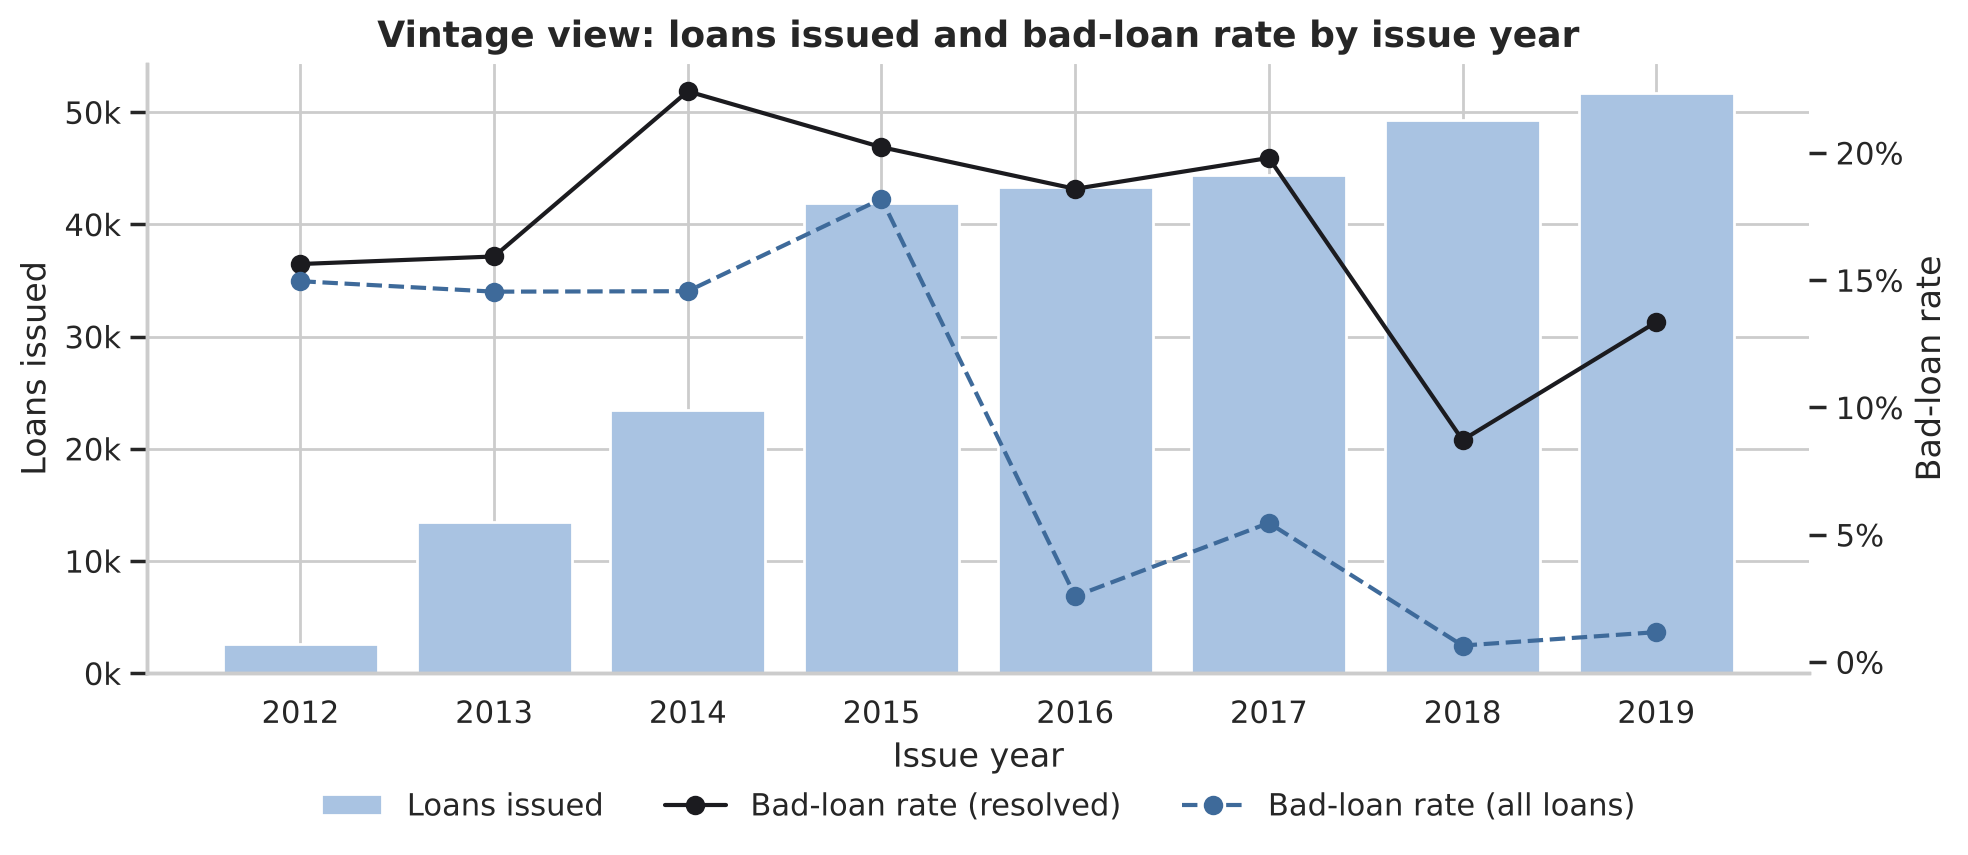

In [29]:
vint = clean.groupby("issue_year").agg(loans=("loan_id", "size"))
vint["bad_rate_resolved"] = res.groupby("issue_year")["bad_flag"].mean()
vint["bad_rate_all"] = clean.groupby("issue_year")["bad_flag"].mean()
display(vint.style.format({"loans": "{:,}", "bad_rate_resolved": "{:.1%}", "bad_rate_all": "{:.1%}"}))

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(vint.index, vint["loans"], color=GS_LIGHT, label="Loans issued")
ax1.set(title="Vintage view: loans issued and bad-loan rate by issue year", xlabel="Issue year", ylabel="Loans issued")
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v/1000:,.0f}k"))
ax2 = ax1.twinx()
ax2.plot(vint.index, vint["bad_rate_resolved"], color=GS_BLACK, marker="o", label="Bad-loan rate (resolved)")
ax2.plot(vint.index, vint["bad_rate_all"], color=GS_DEEP, marker="o", ls="--", label="Bad-loan rate (all loans)")
ax2.yaxis.set_major_formatter(pct); ax2.set_ylabel("Bad-loan rate"); ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
save("18_vintage")

**Observation:** loans issued rose 20 times from 2012 to 2019; on the all-loans base 2018 looks almost risk-free (0.6%) but on finished loans it is 8.7%, proving the resolved base is the honest measure.

## 7. Testing five statements

### Statement 1: 60-month loans go bad more often than 36-month loans within the same grade

term_months,36,60,gap_pts,60m_worse
grade,,,,
A,5.7%,9.0%,+3.2,True
B,11.7%,16.1%,+4.4,True
C,18.8%,26.8%,+8.0,True
D,25.4%,33.9%,+8.5,True
E,31.7%,42.3%,+10.6,True
F,39.7%,47.9%,+8.3,True
G,45.9%,48.6%,+2.6,True


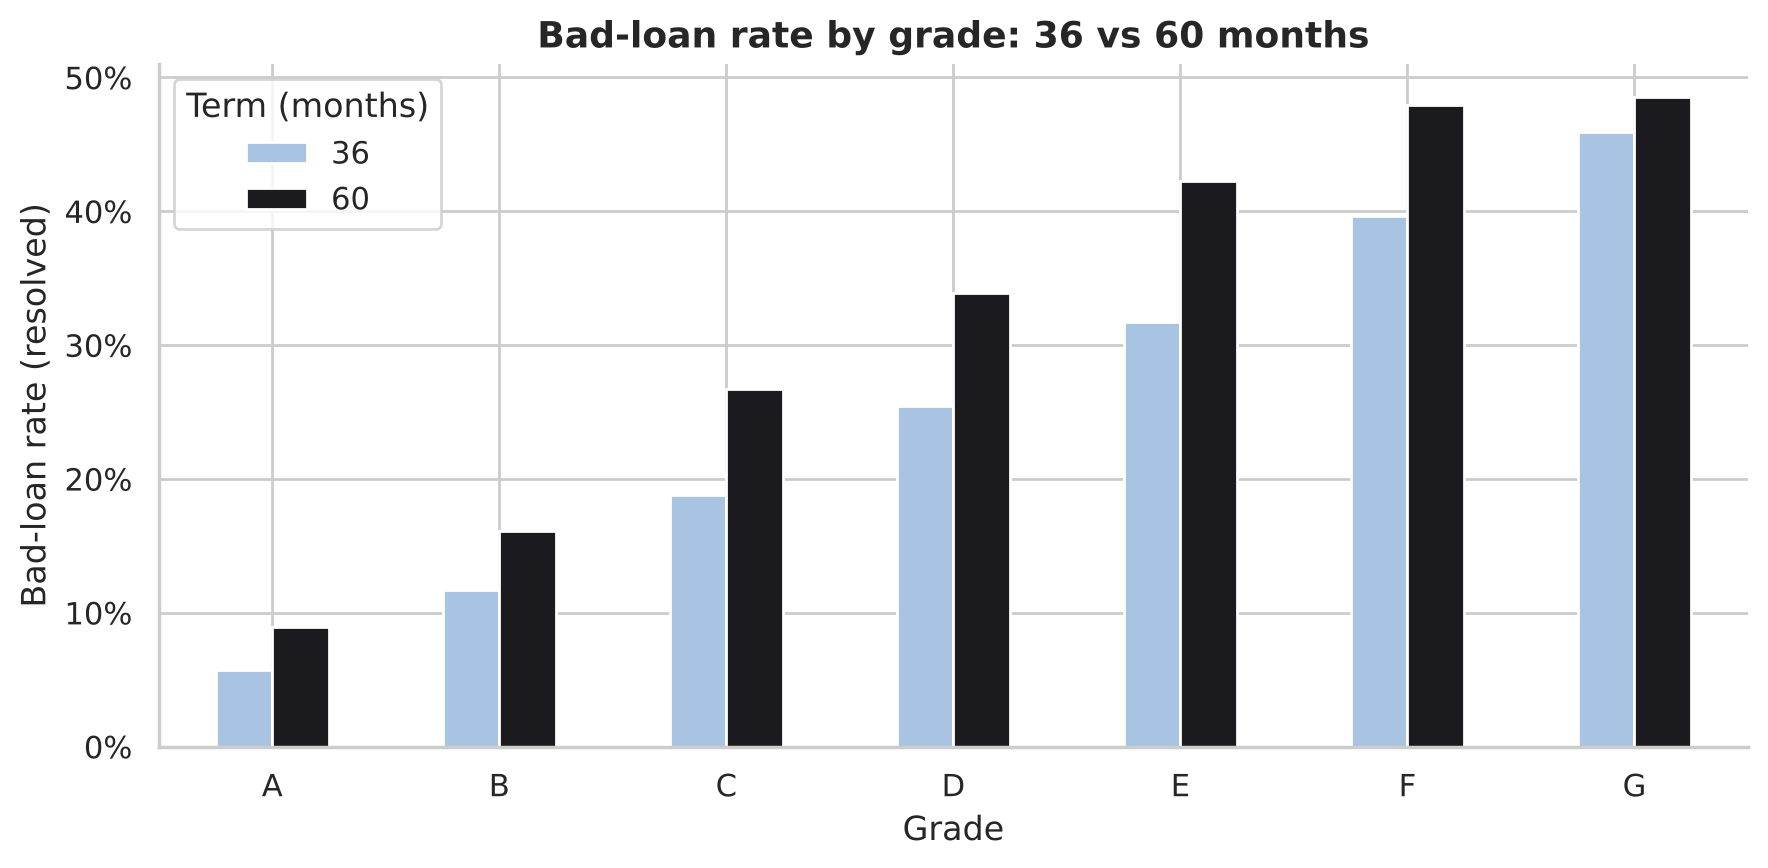

In [30]:
s1 = grade_term.copy()
s1["gap_pts"] = (s1[60] - s1[36]) * 100
s1["60m_worse"] = s1[60] > s1[36]
display(s1.style.format({36: "{:.1%}", 60: "{:.1%}", "gap_pts": "{:+.1f}"}))

ax = s1[[36, 60]].plot(kind="bar", color=[GS_LIGHT, GS_BLACK], figsize=(9, 4.5), rot=0)
ax.set(title="Bad-loan rate by grade: 36 vs 60 months", xlabel="Grade", ylabel="Bad-loan rate (resolved)")
ax.yaxis.set_major_formatter(pct); ax.legend(title="Term (months)")
save("19_s1_term_within_grade")

**Verdict: holds.** In all seven grades the 60-month rate is higher, by 2.6 points at G up to 10.6 points at E (grade C: 26.8% vs 18.8%).

### Statement 2: Bad-loan rate falls steadily as income rises

,bad_rate,resolved,change_pts
income_band,,,
<45k,22.6%,"20,388",
45k-60k,20.7%,"18,483",-1.9
60k-75k,19.3%,"17,386",-1.4
75k-100k,17.3%,"18,062",-2.1
100k+,14.8%,"19,905",-2.5


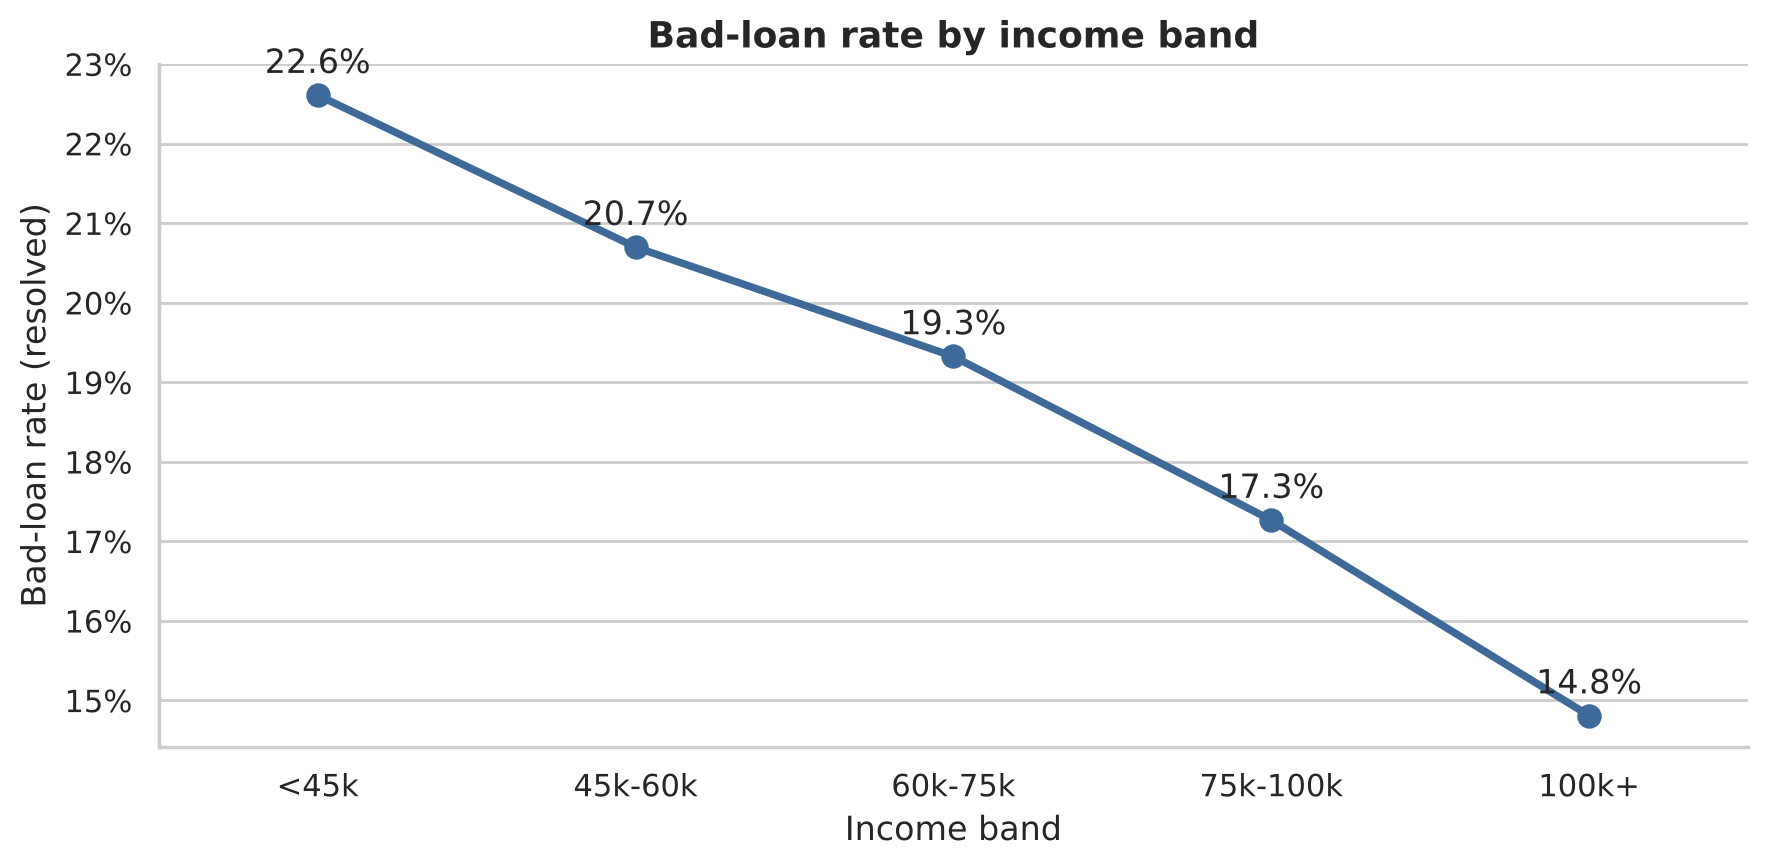

In [31]:
s2 = res.groupby("income_band", observed=True)["bad_flag"].agg(bad_rate="mean", resolved="size")
s2["change_pts"] = s2["bad_rate"].diff() * 100
display(s2.style.format({"bad_rate": "{:.1%}", "resolved": "{:,}", "change_pts": "{:+.1f}"}, na_rep=""))

ax = sns.pointplot(x=s2.index.astype(str), y=s2["bad_rate"], color=GS_DEEP)
ax.set(title="Bad-loan rate by income band", xlabel="Income band", ylabel="Bad-loan rate (resolved)")
ax.yaxis.set_major_formatter(pct)
for i, v in enumerate(s2["bad_rate"]): ax.annotate(f"{v:.1%}", (i, v), textcoords="offset points", xytext=(0, 8), ha="center")
save("20_s2_income")

**Verdict: holds.** Every step up in income lowers the rate: 22.6%, 20.7%, 19.3%, 17.3%, 14.8%, a drop of 7.8 points from the lowest to the highest band.

### Statement 3: Small-business loans are the riskiest purpose

,bad_rate,resolved
purpose,,
Small Business,27.2%,938
Moving,21.5%,687
Debt Consolidation,20.3%,"55,174"
Medical,19.7%,"1,044"
Other,19.3%,"5,126"


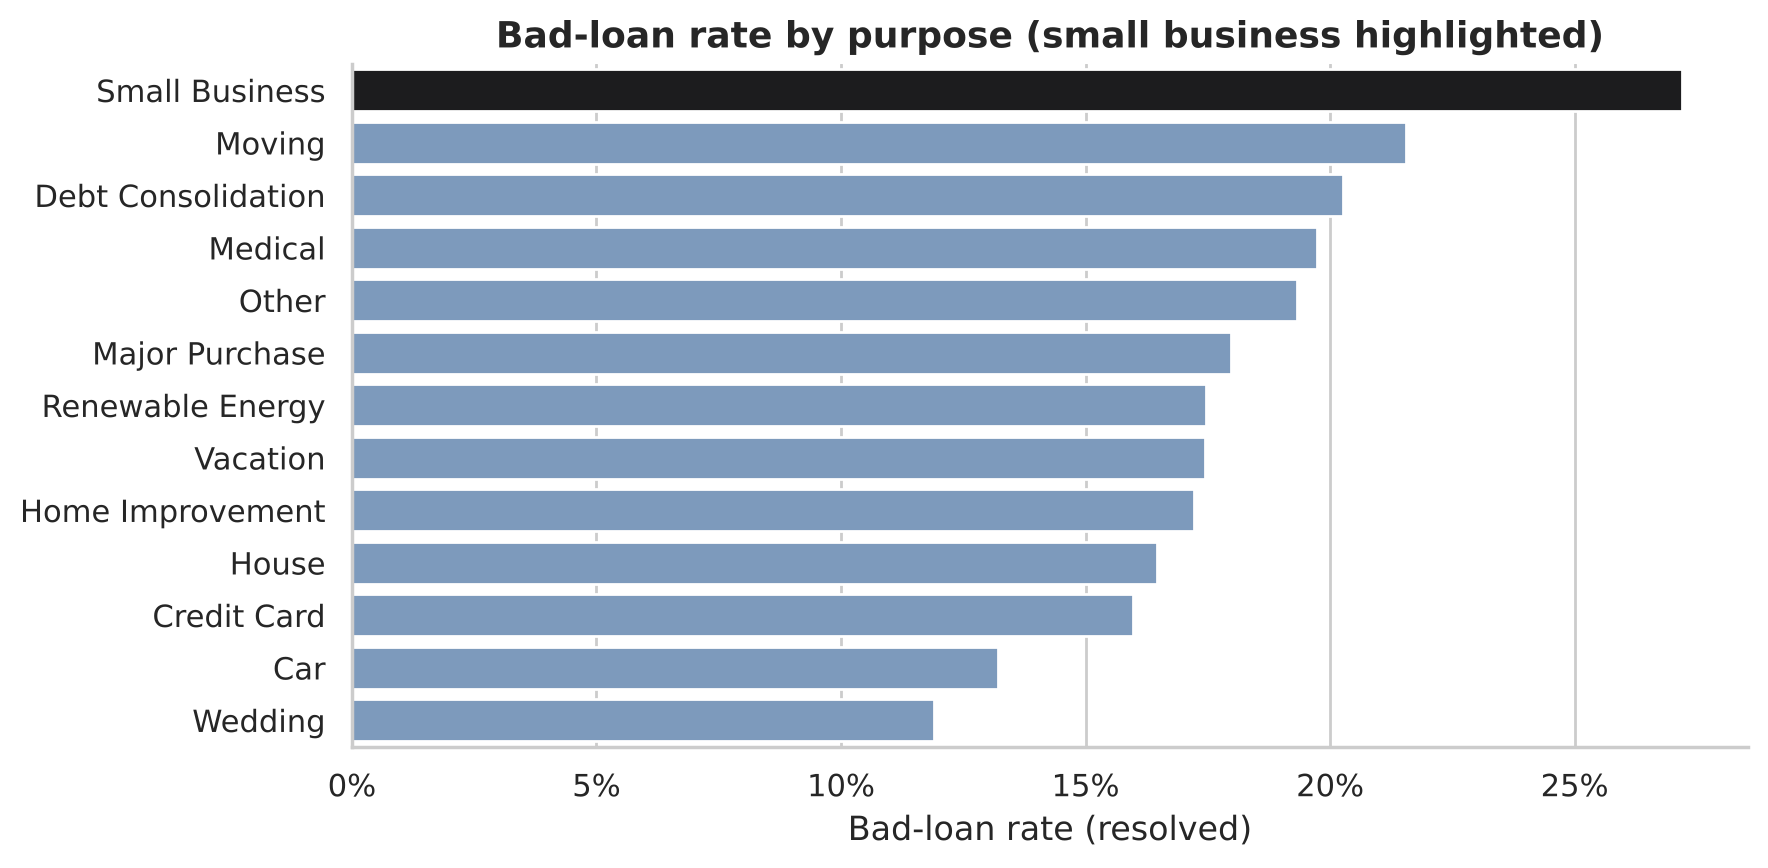

In [32]:
s3 = res.groupby("purpose")["bad_flag"].agg(bad_rate="mean", resolved="size").sort_values("bad_rate", ascending=False)
display(s3.head(5).style.format({"bad_rate": "{:.1%}", "resolved": "{:,}"}))

colors = [GS_BLACK if p == "Small Business" else GS_BLUE for p in s3.index]
ax = sns.barplot(y=s3.index, x=s3["bad_rate"], palette=colors, hue=s3.index, legend=False)
ax.set(title="Bad-loan rate by purpose (small business highlighted)", xlabel="Bad-loan rate (resolved)", ylabel="")
ax.xaxis.set_major_formatter(pct)
save("21_s3_purpose")

**Verdict: holds.** Small business has the highest bad-loan rate (27.2%), 5.7 points above the next purpose (moving, 21.5%) and 8.2 points above the portfolio.

### Statement 4: Higher PTI means higher risk at every level

,bad_rate,resolved
pti_band,,
<5%,12.8%,"26,864"
5-10%,18.8%,"40,751"
10-15%,25.2%,"20,228"
15-20%,26.4%,"5,489"
20%+,24.6%,892


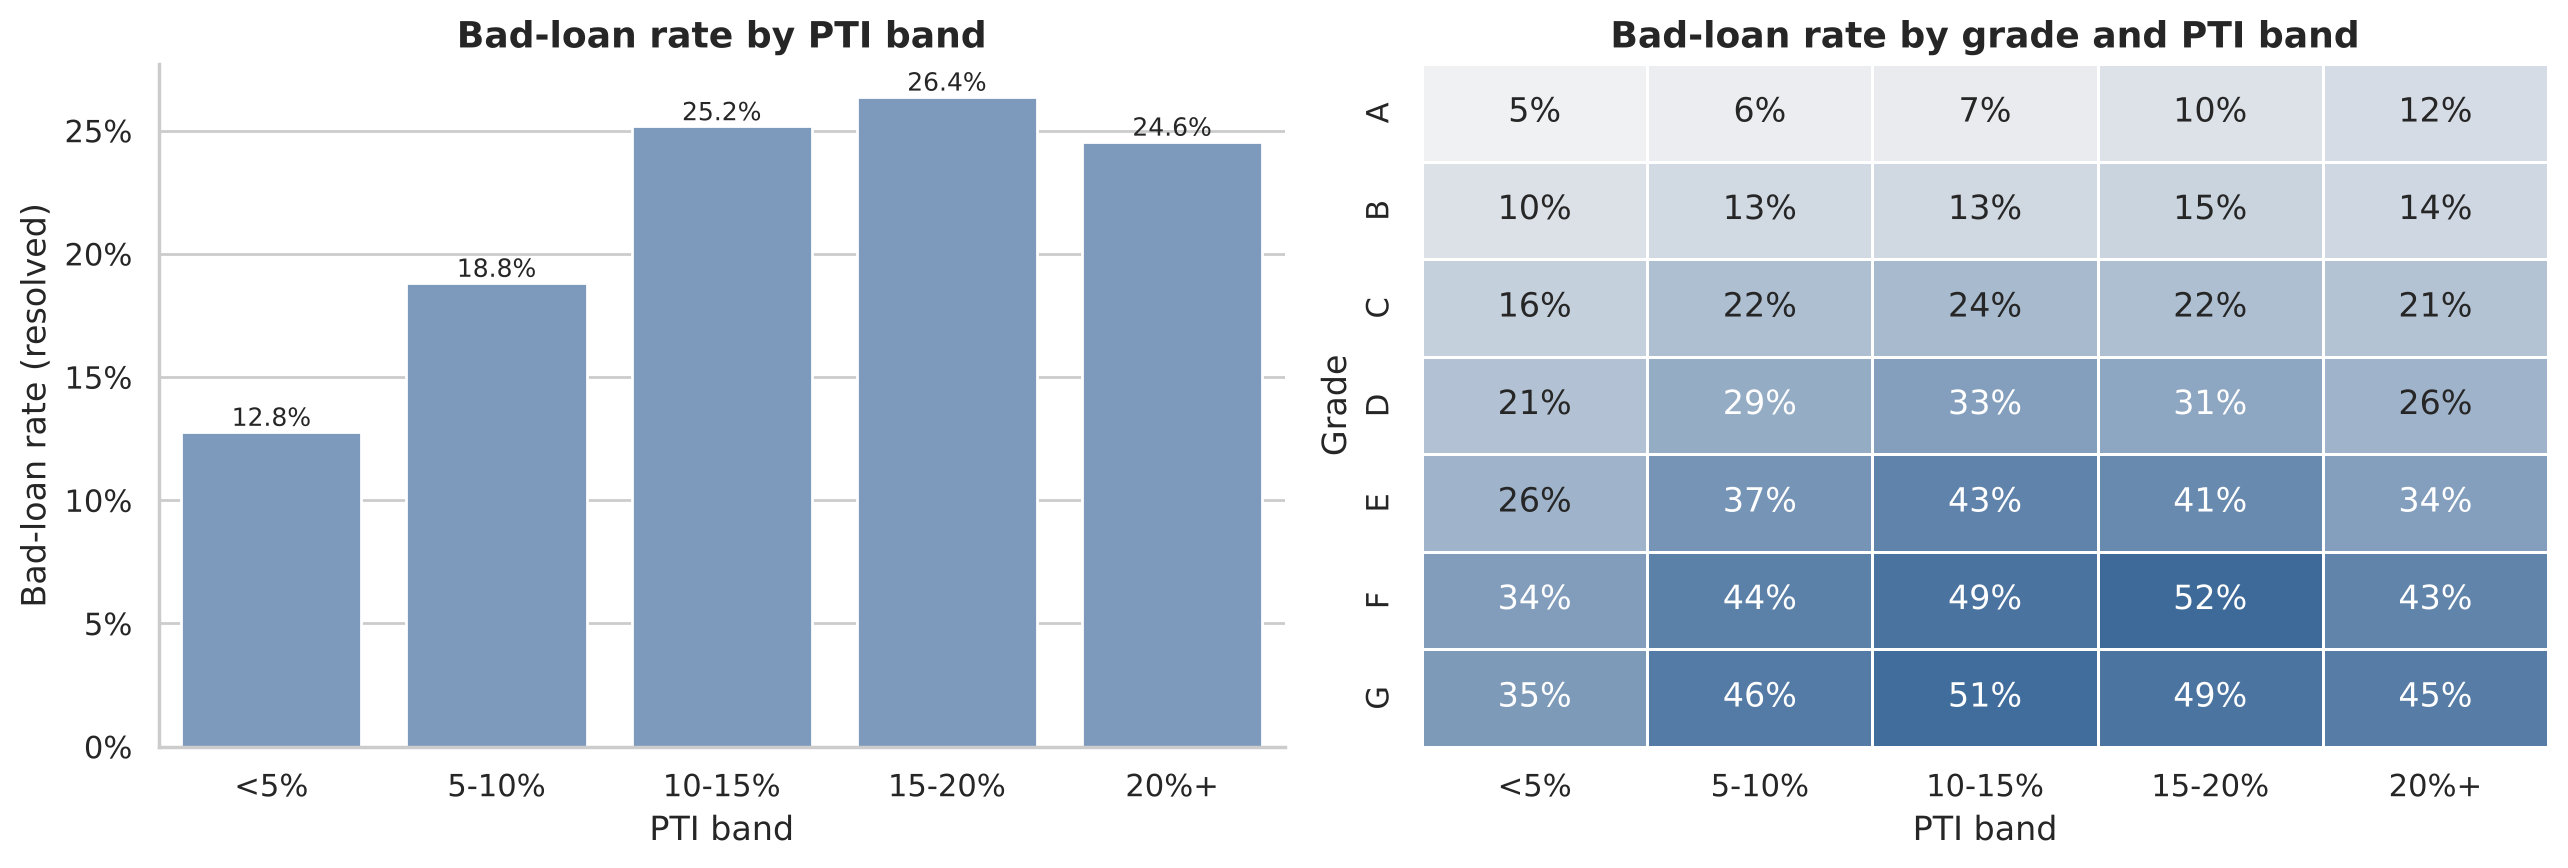

In [33]:
s4 = res.groupby("pti_band", observed=True)["bad_flag"].agg(bad_rate="mean", resolved="size")
display(s4.style.format({"bad_rate": "{:.1%}", "resolved": "{:,}"}))
s4g = res.pivot_table(index="grade", columns="pti_band", values="bad_flag", aggfunc="mean", observed=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=s4.index.astype(str), y=s4["bad_rate"], color=GS_BLUE, ax=ax[0])
ax[0].set(title="Bad-loan rate by PTI band", xlabel="PTI band", ylabel="Bad-loan rate (resolved)")
ax[0].yaxis.set_major_formatter(pct)
ax[0].bar_label(ax[0].containers[0], labels=[f"{v:.1%}" for v in s4["bad_rate"]], fontsize=9)
sns.heatmap(s4g, annot=True, fmt=".0%", cmap=GS_SEQ, ax=ax[1], cbar=False, linewidths=.5)
ax[1].set(title="Bad-loan rate by grade and PTI band", xlabel="PTI band", ylabel="Grade")
save("22_s4_pti")

**Verdict: does not hold at every level.** Risk rises from 12.8% (PTI under 5%) to 26.4% (15-20%), then dips to 24.6% above 20%. Within grades C to G the peak is at 10-20% PTI, so PTI matters most at the low end and flattens out once payments pass about 15% of income.

### Statement 5: Region makes little difference to risk once grade is taken into account

region,Midwest,Northeast,South,West,spread_pts
grade,,,,,
A,6.1%,6.6%,5.8%,5.1%,1.4
B,12.0%,12.8%,12.3%,11.9%,0.9
C,21.7%,22.3%,21.1%,19.3%,3.0
D,29.4%,29.5%,29.2%,26.2%,3.4
E,38.7%,39.9%,38.4%,35.9%,4.0
F,48.5%,47.3%,47.5%,41.6%,7.0
G,50.9%,50.0%,46.6%,47.4%,4.3


Spread across grades: 42.3 points. Average spread across regions within a grade: 3.4 points.


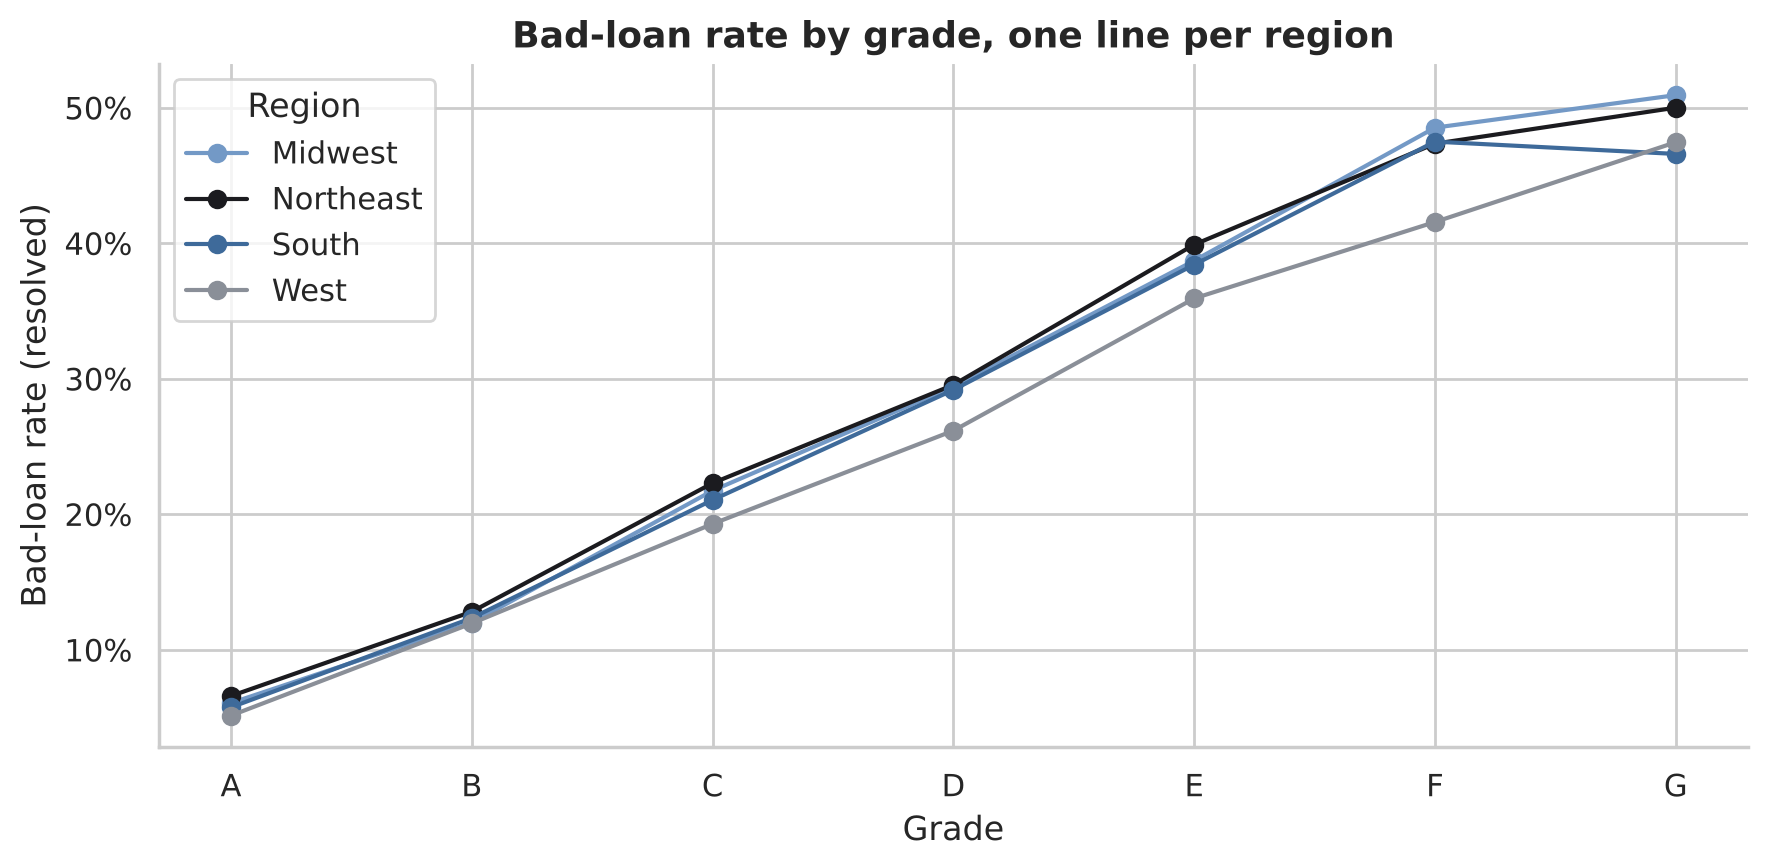

In [34]:
s5 = res.pivot_table(index="grade", columns="region", values="bad_flag", aggfunc="mean")
s5["spread_pts"] = (s5.max(axis=1) - s5.min(axis=1)) * 100
display(s5.style.format("{:.1%}", subset=["Midwest", "Northeast", "South", "West"]).format("{:.1f}", subset=["spread_pts"]))
grade_spread = (res.groupby("grade")["bad_flag"].mean().max() - res.groupby("grade")["bad_flag"].mean().min()) * 100
print(f"Spread across grades: {grade_spread:.1f} points. Average spread across regions within a grade: {s5['spread_pts'].mean():.1f} points.")

ax = s5.drop(columns="spread_pts").plot(marker="o", color=[GS_BLUE, GS_BLACK, GS_DEEP, GS_GREY], figsize=(9, 4.5))
ax.set(title="Bad-loan rate by grade, one line per region", xlabel="Grade", ylabel="Bad-loan rate (resolved)")
ax.yaxis.set_major_formatter(pct); ax.legend(title="Region")
save("23_s5_region_grade")

**Verdict: holds.** Inside each grade the four regions sit within 3.4 points of each other on average, against a 42-point spread across grades. The West is slightly safer in every grade, but grade explains far more than region.

### Summary of the five statements

| # | Statement | Verdict | Key number |
|---|---|---|---|
| 1 | 60-month loans go bad more often within the same grade | Holds | Higher in all 7 grades; grade C 26.8% vs 18.8% |
| 2 | Bad-loan rate falls steadily as income rises | Holds | 22.6% under $45k down to 14.8% at $100k+ |
| 3 | Small business is the riskiest purpose | Holds | 27.2%, top of 13 purposes |
| 4 | Higher PTI means higher risk at every level | Partly | Rises to 26.4% at 15-20% PTI, then dips to 24.6% |
| 5 | Region makes little difference once grade is known | Holds | 3.4-point regional spread vs 42 points across grades |

## 8. Export loans_clean.csv

In [35]:
export_cols = ["loan_id", "issue_d", "issue_year", "issue_month", "issue_ym", "state", "subregion", "region",
               "loan_status", "grade", "purpose", "type", "term_months", "loan_amount", "funded_amount",
               "int_rate", "installment", "scheduled_interest", "emp_title", "emp_years", "emp_length_missing",
               "home_ownership", "annual_inc", "annual_inc_capped", "income_band", "has_joint_income",
               "verification_status", "zip_code", "avg_cur_bal", "Tot_cur_bal", "pymnt_plan",
               "pti", "pti_band", "bad_flag", "resolved_flag", "delinquent_flag", "npl_flag", "high_risk_flag"]
out = clean[export_cols].copy()
out["issue_d"] = out["issue_d"].dt.strftime("%Y-%m-%d")
out["pti"] = out["pti"].round(4)
out["scheduled_interest"] = out["scheduled_interest"].round(2)
os.makedirs("outputs", exist_ok=True)
out.to_csv("outputs/loans_clean.csv.zip", index=False, compression={"method": "zip", "archive_name": "loans_clean.csv"})
print(f"loans_clean.csv: {out.shape[0]:,} rows x {out.shape[1]} columns, saved zipped to outputs/loans_clean.csv.zip ({os.path.getsize('outputs/loans_clean.csv.zip')/1e6:.1f} MB)")

loans_clean.csv: 270,299 rows x 38 columns, saved zipped to outputs/loans_clean.csv.zip (14.0 MB)


**Note:** `customer_id` is left out of the export. It is a long encoded string that adds about 13 MB, and Part 4 must never send customer IDs to an AI tool, so `loan_id` is kept as the row key instead.

**Next:** Part 4 reads `loans_clean.csv` for the risk explainer prompts and the delinquency watchlist automation.